In [ ]:
!pip install scikit-learn-extra
!pip install scikit-posthocs

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 819.0/819.0 kB 2.7 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for scikit-learn-extra: filename=scikit_learn_extra-0.3.0-cp313-cp313-linux_x86_64.whl size=2156376 sha256=e12d0c3986db60728b677dd8cfdd72c04f97543781c89465c5b8292a3d48b398
  Stored in directory: /root/.cache/pip/wheels/17/4b/b8/6b6711681d0981b110c9cc91ad6d1ebd88adf1547e1da301fc
Successfully built scikit-learn-extra


In [ ]:
# Importação de bibliotecas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
from matplotlib.patches import Ellipse
import seaborn as sns
import re
import warnings
import textwrap
import unicodedata
from itertools import combinations
from scipy import stats
from scipy.stats import chi2_contingency, ttest_ind, kruskal
from scipy.spatial.distance import pdist, squareform
from pathlib import Path
from IPython.display import Markdown, display
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import ConfusionMatrixDisplay, silhouette_score, davies_bouldin_score, calinski_harabasz_score, pairwise_distances, adjusted_rand_score
from sklearn_extra.cluster import KMedoids
import scikit_posthocs as sp
import statsmodels.formula.api as smf
import statsmodels.api as sm

In [ ]:
# df.to_csv('coleta.csv', index=False)

from pathlib import Path

arquivos_xlsx = list(Path.cwd().glob('*.xlsx'))
if len(arquivos_xlsx) != 1:
    raise RuntimeError(f'Esperado exatamente um arquivo .xlsx, encontrados: {len(arquivos_xlsx)}')

arquivo_dados = arquivos_xlsx[0]
df_raw = pd.read_excel(arquivo_dados)
df = df_raw.copy()
print(f'Base carregada: {arquivo_dados.name} - {df.shape[0]} respostas, {df.shape[1]} colunas')

Base carregada: coleta.xlsx - 192 respostas, 33 colunas


In [ ]:
df.shape

(192, 33)

In [ ]:
df = df.drop(columns=['Hora de início',
                      'Hora de conclusão',
                      'Email',
                      'Nome',
                      'Hora da última modificação',
                      'Li e concordo em participar',
                      'Tenho 18 anos ou mais',
                      'Autorizo o uso acadêmico e publicação de resultados agregados e anônimos.']) #	Remover colunas que não serão usadas na análise,

In [ ]:
df['Instituição'] = df['Instituição'].str.strip()
df['Instituição'].unique()

array(['UPM', 'Mackenzie', 'Ufabc', 'Macknzie', 'FCI'], dtype=object)

In [ ]:
mack_var = ['Mackenzie', 'Mackenzie ','Macknzie','FCI','Universidade Presbiteriana Mackenzie ']

mack_mapa = {mack: 'UPM' for mack in mack_var}

df['Instituição'] = df['Instituição'].replace(mack_mapa)

In [ ]:
df = df[df['Instituição'] == 'UPM']

In [ ]:
df['Curso/Faculdade'] = df['Curso/Faculdade'].str.strip()
df['Curso/Faculdade'].unique()

array(['FCI (Ciência da Computação/Sistemas de Informação)',
       'Banco de dados', 'Tecnologia em Banco de Dados', 'Direito',
       'direito FDIR', 'DIREITO', 'Licenciatura em Matemática',
       'FCI Banco de Dados', 'Análise e Desenvolvimentos de Sistemas',
       'Analise e desenvolvimento de sistemas', 'Ciência/Banco de Dados',
       'Análise e Desenvolvimento de Sistemas',
       'Análise Desenvolvimento de Sistemas', 'Banco de Dados',
       'FCI (Banco de Dados)', 'ADS', 'PP',
       'Tecnologia em Banco de Dados: Análise, Mineração e Engenharia de Dados',
       'ads', 'Nutrição', 'MKT', 'Ccbs- nutrição',
       'Dupla titulação direito e nutrição', 'CCBS / Nutrição',
       'CCBS (Nutrição)', 'nutrição', 'NUTRIÇÃO'], dtype=object)

In [ ]:
fci_var = ['FCI (Ciência da Computação/Sistemas de Informação)']

fdir_var = ['Direito', 'direito FDIR', 'DIREITO']

ead_var = ['Banco de dados', 'Tecnologia em Banco de Dados', 'Licenciatura em Matemática','FCI Banco de Dados', 'Análise e Desenvolvimentos de Sistemas',
       'Analise e desenvolvimento de sistemas', 'Ciência/Banco de Dados',
       'Análise e Desenvolvimento de Sistemas',
       'Análise Desenvolvimento de Sistemas', 'Banco de Dados',
       'FCI (Banco de Dados)', 'ADS','Tecnologia em Banco de Dados: Análise, Mineração e Engenharia de Dados', 'ads']

pp_var = ['PP','MKT']

nutri_var = ['Nutrição', 'Ccbs- nutrição',
       'Dupla titulação direito e nutrição', 'CCBS / Nutrição',
       'CCBS (Nutrição)', 'nutrição', 'NUTRIÇÃO']

cursos_mapa = {**{fci: 'FCI' for fci in fci_var},
               **{ead: 'EaD' for ead in ead_var},
               **{fdir: 'FDIR' for fdir in fdir_var},
               **{pp: 'CCL' for pp in pp_var},
               **{nutri: 'CCBS' for nutri in nutri_var}}

df['Curso/Faculdade'] = df['Curso/Faculdade'].replace(cursos_mapa) # 2)	Padronizar categorias inconsistentes: a.	Por exemplo: cursos como “Direito”, “direito FDIR” e “DIREITO” deveriam ser padronizados;

In [ ]:
df.isnull().sum() #3)	Verificar se há dado faltante e tratar.

,0
ID,0
Instituição,0
Campus,0
Curso/Faculdade,0
Área de Conhecimento,0
Turno,0
Semestre Atual,0
Trabalha atualmente?,0
Horas de sono por noite,0
Qualidade do sono (últimas 2 semanas),0


In [ ]:
df.dropna(inplace=True)

In [ ]:
gad7_mapa = {
    '': 0,
    'Nunca': 0,
    'Vários dias': 1,
    'Mais da metade dos dias': 2,
    'Quase todos os dias': 3}

colunas_gad7 = [
    'Sentir-se nervoso(a), ansioso(a) ou “no limite”.',
    'Não conseguir parar ou controlar a preocupação.',
    'Preocupar-se demais com diferentes coisas.',
    'Dificuldade para relaxar.',
    'Ficar tão agitado(a) que é difícil permanecer sentado(a) parado(a).',
    'Tornar-se facilmente irritado(a) ou impaciente.',
    'Sentir medo como se algo terrível pudesse acontecer.'
]

df[colunas_gad7] = (
    df[colunas_gad7]
    .replace(gad7_mapa)
    .astype(int)
)

/tmp/ipykernel_714/706997145.py:20: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .replace(gad7_mapa)


In [ ]:
df['Curso/Faculdade'].value_counts()

,count
Curso/Faculdade,
FCI,146
EaD,20
CCBS,12
FDIR,6
CCL,2


In [ ]:
# Análise de dados instituicionais

institucionais = ['Curso/Faculdade','Turno','Semestre Atual','Trabalha atualmente?']

for i in institucionais:
    print((df[i].value_counts()))
    print()

Curso/Faculdade
FCI     146
EaD      20
CCBS     12
FDIR      6
CCL       2
Name: count, dtype: int64

Turno
Noturno       110
Matutino       67
Integral        6
Vespertino      3
Name: count, dtype: int64

Semestre Atual
1-2                     52
3-4                     45
5-6                     43
7-8                     38
Prefiro não informar     7
9+                       1
Name: count, dtype: int64

Trabalha atualmente?
Sim, integral           77
Não                     53
Sim, meio período       50
Prefiro não informar     6
Name: count, dtype: int64



In [ ]:
# Análise de dados de hábitos de vida
habitos = ['Horas de sono por noite','Qualidade do sono (últimas 2 semanas)','Atividade física semanal','Alimentação adequada (autoavaliação)']

for h in habitos:
    print((df[h].value_counts(normalize=True) * 100).map(lambda x : f"{x:.2f}%"))
    print()

Horas de sono por noite
5-6    48.92%
7-8    31.18%
<5     16.13%
>8      3.76%
Name: proportion, dtype: object

Qualidade do sono (últimas 2 semanas)
Regular    43.55%
Ruim       23.12%
Boa        17.20%
Ótima       9.14%
Péssima     6.99%
Name: proportion, dtype: object

Atividade física semanal
0 dias      37.10%
1-2 dias    28.49%
3-4 dias    23.12%
> 5 dias    11.29%
Name: proportion, dtype: object

Alimentação adequada (autoavaliação)
Média          52.15%
Alta           20.97%
Baixa          15.59%
Muito baixa     6.99%
Muito Alta      4.30%
Name: proportion, dtype: object



In [ ]:
# Análise de dados acadêmicos
academicos = ['Carga diária de estudos fora da aula','Tempo de lazer/descanso por dia','Média de notas','Faltas recorrentes neste semestre','Trancou disciplina no último ano?','Atividades complementares/monitoria/iniciação']

for a in academicos:
    print((df[a].value_counts(normalize=True) * 100).map(lambda x : f"{x:.2f}%"))
    print()

Carga diária de estudos fora da aula
1-2 horas    51.61%
<1 hora      24.73%
3-4 horas    16.13%
>4 horas      7.53%
Name: proportion, dtype: object

Tempo de lazer/descanso por dia
30-60 minutos    30.65%
>2 horas         27.42%
1-2 horas        26.88%
<30 minutos      15.05%
Name: proportion, dtype: object

Média de notas
≥8,0                    45.16%
7,0–7,9                 25.27%
6,0–6,9                 17.20%
Prefiro não informar     8.60%
<5,9                     3.76%
Name: proportion, dtype: object

Faltas recorrentes neste semestre
Eu não falto nunca    34.41%
1%-5%                 31.18%
6%-10%                13.98%
11%-15%               12.37%
16%-20%                4.84%
>20%                   3.23%
Name: proportion, dtype: object

Trancou disciplina no último ano?
Não    85.48%
Sim    14.52%
Name: proportion, dtype: object

Atividades complementares/monitoria/iniciação
Sim    51.61%
Não    48.39%
Name: proportion, dtype: object



### Escala GAD-7

+0: Nunca;

+1: Vários dias;

+2: Mais da metade dos dias;

+3: Quase todos os dias;

Pontuação de 0 a 4: Ansiedade mínima;

Pontuação de 5 a 9: Ansiedade Leve;

Pontuação de 10 a 14: Ansiedade Moderada;

Pontuação de 15 a 21: Ansiedade grave;

In [ ]:
# Calcular o escore GAD-7, converter as respostas dos 7 itens do GAD-7 em pontuações.
df['Score GAD-7'] = df['Sentir-se nervoso(a), ansioso(a) ou “no limite”.'] + df['Não conseguir parar ou controlar a preocupação.'] + df['Preocupar-se demais com diferentes coisas.'] + df['Dificuldade para relaxar.'] + df['Ficar tão agitado(a) que é difícil permanecer sentado(a) parado(a).'] + df['Tornar-se facilmente irritado(a) ou impaciente.'] + df['Sentir medo como se algo terrível pudesse acontecer.']

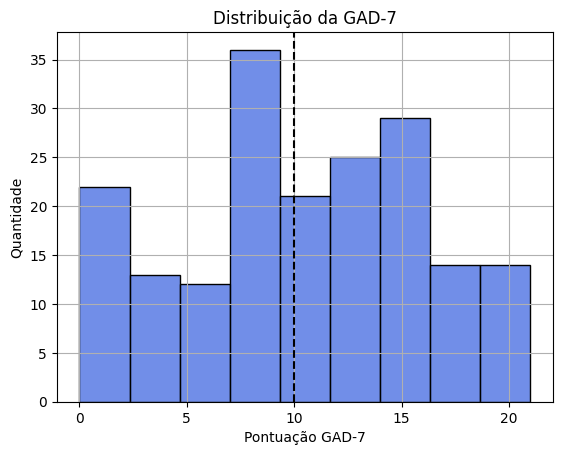

In [ ]:
# Como está distribuído o GAD-7? Pensar em um histograma do escore total e gráfico de barras com as quatro categorias: mínima, leve, moderada e grave.
sns.histplot(x=df['Score GAD-7'],color='royalblue')
plt.title("Distribuição da GAD-7")
plt.xlabel("Pontuação GAD-7")
plt.ylabel("Quantidade")
plt.axvline(x=10, color='black', linestyle='--')
plt.grid()
plt.show()

In [ ]:
nivel_cores = {
    'Mínima': 'green',
    'Leve': 'yellow',
    'Moderada': 'orange',
    'Grave': 'red'
}

df['Nível'] = pd.cut(df['Score GAD-7'], bins=[-1,4,9,14,21], labels=['Mínima', 'Leve', 'Moderada', 'Grave'])

print(df['Nível'].value_counts())

Nível
Moderada    53
Grave       50
Leve        48
Mínima      35
Name: count, dtype: int64


In [ ]:
ansiedade_cores = {
    'Sem alto risco': 'green',
    'Alto risco': 'red'
}

ansiedade_rotulos = {
    0: 'Sem alto risco',
    1: 'Alto risco'
}

df['Ansiedade'] = (df['Score GAD-7'] >= 10).astype(int)

print(df['Ansiedade'].value_counts())
print(df['Ansiedade'].value_counts(normalize=True))

Ansiedade
1    103
0     83
Name: count, dtype: int64
Ansiedade
1    0.553763
0    0.446237
Name: proportion, dtype: float64


In [ ]:
def add_labels(ax,min=2):
  for container in ax.containers:
    rotulos = []
    for num in container.datavalues:
      if num >= min: rotulo = f'{num:.0f}' + '%'
      else: rotulo = ''
      rotulos.append(rotulo)
    ax.bar_label(container,labels=rotulos,label_type='center')

def place_legends(*ax):
  handles, labels = ax[0].get_legend_handles_labels()
  for a in ax:
    a.get_legend().remove()
  plt.gcf().legend(handles,labels,loc='lower center',ncol=4, bbox_to_anchor=(0.5,0.3))

In [ ]:
df['Nível'].value_counts()

,count
Nível,
Moderada,53
Grave,50
Leve,48
Mínima,35


In [ ]:
df['Nível'].value_counts(normalize=True)

,proportion
Nível,
Moderada,0.284946
Grave,0.268817
Leve,0.258065
Mínima,0.188172


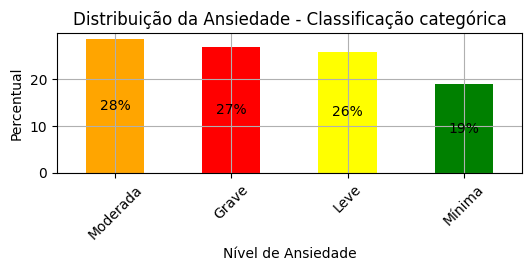

In [ ]:
plt.figure(figsize=(6,4))

ax_geral_cat = plt.subplot(211)
plot_geral_cat = df['Nível'].value_counts(normalize=True) * 100
plot_geral_cat.plot(kind='bar',color=[nivel_cores.get(x,'#333333') for x in plot_geral_cat.index],ax=ax_geral_cat)
ax_geral_cat.set_title("Distribuição da Ansiedade - Classificação categórica")
ax_geral_cat.set_xlabel("Nível de Ansiedade")
ax_geral_cat.set_ylabel("Percentual")
ax_geral_cat.tick_params(axis='x', rotation=45)

add_labels(ax_geral_cat)
plt.grid()
plt.show()

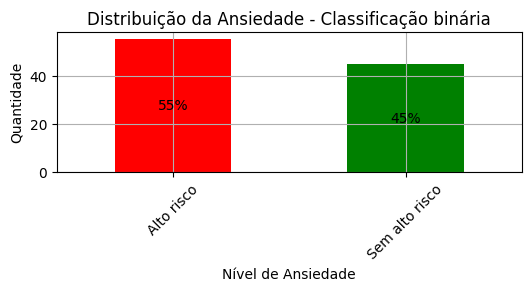

In [ ]:
plt.figure(figsize=(6,4))

ax_geral_bin = plt.subplot(211)
plot_geral_bin = df['Ansiedade'].value_counts(normalize=True) * 100
plot_geral_bin = plot_geral_bin.rename(ansiedade_rotulos)
plot_geral_bin.plot(kind='bar',color=[ansiedade_cores.get(x,'#333333') for x in plot_geral_bin.index],ax=ax_geral_bin)
ax_geral_bin.set_title("Distribuição da Ansiedade - Classificação binária")
ax_geral_bin.set_xlabel("Nível de Ansiedade")
ax_geral_bin.set_ylabel("Quantidade")
ax_geral_bin.tick_params(axis='x', rotation=45)

add_labels(ax_geral_bin)
plt.grid()
plt.show()

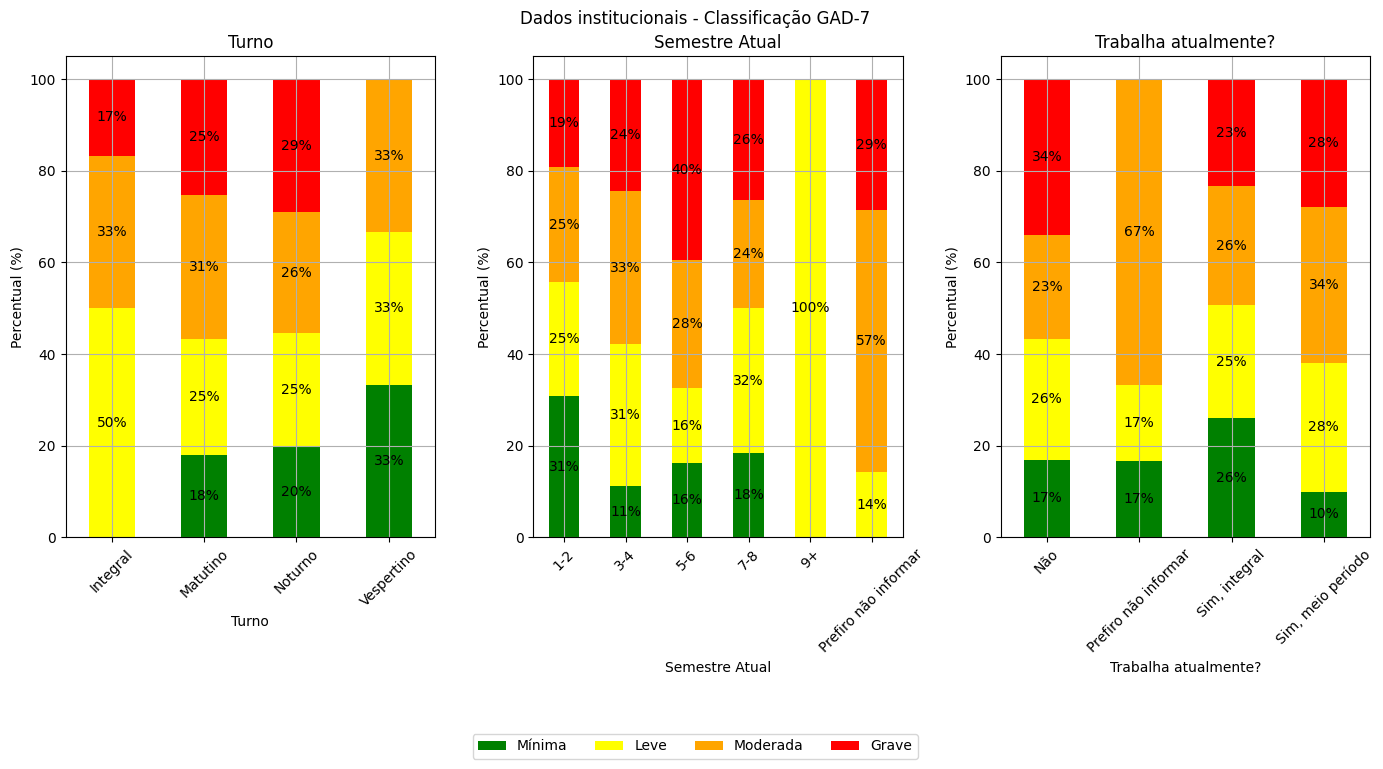

In [ ]:
plt.figure(figsize=(14,12))
plt.suptitle("Dados institucionais - Classificação GAD-7")

ax_instturno_cat = plt.subplot(231)
plot_instturno_cat = pd.crosstab(df['Turno'], df['Nível'], normalize='index') * 100
plot_instturno_cat.plot(kind='bar', stacked=True, color=nivel_cores, ax=ax_instturno_cat)
ax_instturno_cat.set_title("Turno")
ax_instturno_cat.set_xlabel("Turno")
ax_instturno_cat.set_ylabel("Percentual (%)")
ax_instturno_cat.tick_params(axis='x', rotation=45)
ax_instturno_cat.grid()

ax_instsem_cat = plt.subplot(232)
plot_instsem_cat = pd.crosstab(df['Semestre Atual'], df['Nível'], normalize='index') * 100
plot_instsem_cat.plot(kind='bar',  stacked=True, color=nivel_cores, ax=ax_instsem_cat)
ax_instsem_cat.set_title("Semestre Atual")
ax_instsem_cat.set_xlabel("Semestre Atual")
ax_instsem_cat.set_ylabel("Percentual (%)")
ax_instsem_cat.tick_params(axis='x', rotation=45)
ax_instsem_cat.grid()

ax_instwork_cat = plt.subplot(233)
plot_instwork_cat = pd.crosstab(df['Trabalha atualmente?'], df['Nível'], normalize='index') * 100
plot_instwork_cat.plot(kind='bar',  stacked=True, color=nivel_cores, ax=ax_instwork_cat)
ax_instwork_cat.set_title("Trabalha atualmente?")
ax_instwork_cat.set_xlabel("Trabalha atualmente?")
ax_instwork_cat.set_ylabel("Percentual (%)")
ax_instwork_cat.tick_params(axis='x', rotation=45)
ax_instwork_cat.grid()

ax_instturno_cat.legend().remove()
ax_instsem_cat.legend().remove()
ax_instwork_cat.legend().remove()
handles, labels = ax_instturno_cat.get_legend_handles_labels()
plt.gcf().legend(handles,labels,loc='lower center',ncols=4,bbox_to_anchor=(0.5,0.35))
add_labels(ax_instturno_cat)
add_labels(ax_instsem_cat)
add_labels(ax_instwork_cat)
plt.tight_layout()
plt.show()

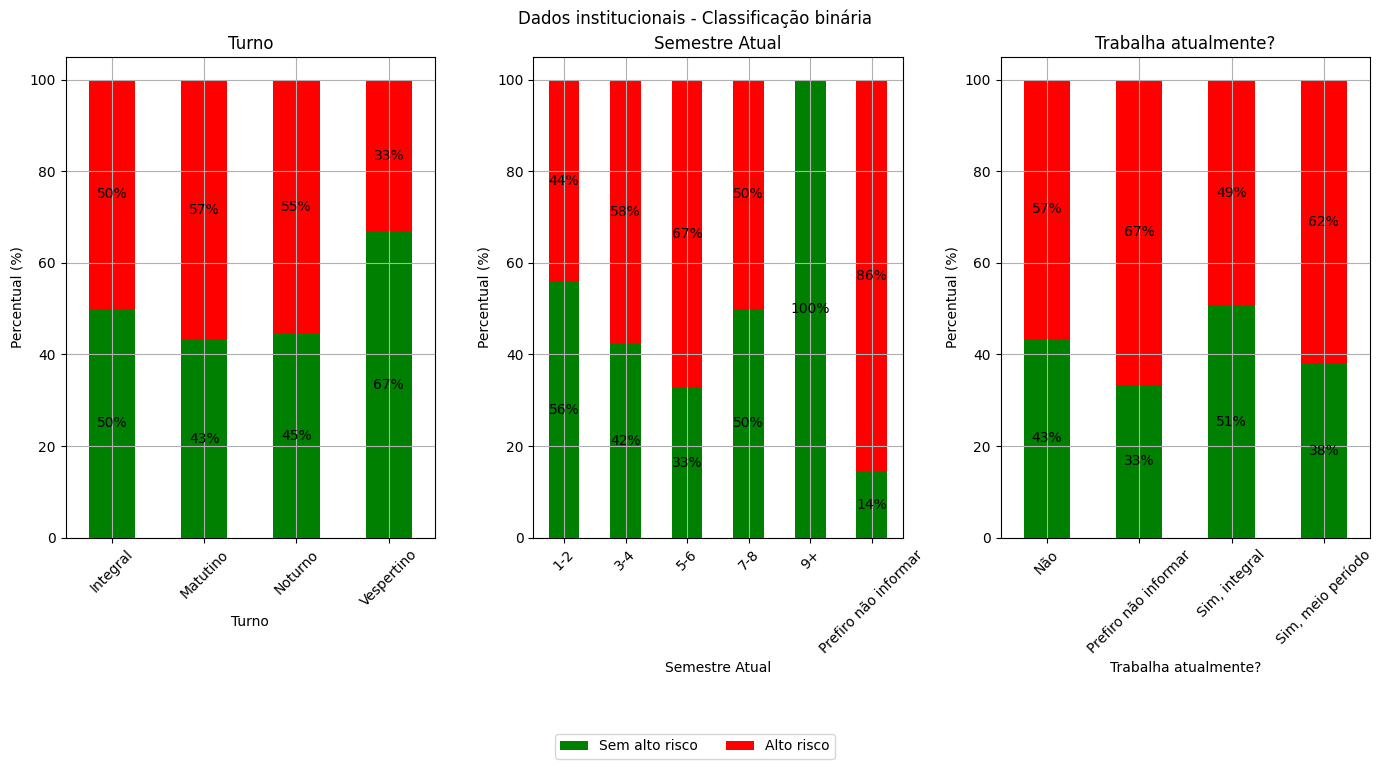

In [ ]:
plt.figure(figsize=(14,12))
plt.suptitle("Dados institucionais - Classificação binária")

ax_instturno_bin = plt.subplot(231)
plot_instturno_bin = pd.crosstab(df['Turno'], df['Ansiedade'], normalize='index') * 100
plot_instturno_bin = plot_instturno_bin.rename(columns=ansiedade_rotulos)
plot_instturno_bin.plot(kind='bar', stacked=True, color=ansiedade_cores, ax=ax_instturno_bin)
ax_instturno_bin.set_title("Turno")
ax_instturno_bin.set_xlabel("Turno")
ax_instturno_bin.set_ylabel("Percentual (%)")
ax_instturno_bin.tick_params(axis='x', rotation=45)
ax_instturno_bin.grid()

ax_instsem_bin = plt.subplot(232)
plot_instsem_bin = pd.crosstab(df['Semestre Atual'], df['Ansiedade'], normalize='index') * 100
plot_instsem_bin = plot_instsem_bin.rename(columns=ansiedade_rotulos)
plot_instsem_bin.plot(kind='bar',  stacked=True, color=ansiedade_cores, ax=ax_instsem_bin)
ax_instsem_bin.set_title("Semestre Atual")
ax_instsem_bin.set_xlabel("Semestre Atual")
ax_instsem_bin.set_ylabel("Percentual (%)")
ax_instsem_bin.tick_params(axis='x', rotation=45)
ax_instsem_bin.grid()

ax_instwork_bin = plt.subplot(233)
plot_instwork_bin = pd.crosstab(df['Trabalha atualmente?'], df['Ansiedade'], normalize='index') * 100
plot_instwork_bin = plot_instwork_bin.rename(columns=ansiedade_rotulos)
plot_instwork_bin.plot(kind='bar',  stacked=True, color=ansiedade_cores, ax=ax_instwork_bin)
ax_instwork_bin.set_title("Trabalha atualmente?")
ax_instwork_bin.set_xlabel("Trabalha atualmente?")
ax_instwork_bin.set_ylabel("Percentual (%)")
ax_instwork_bin.tick_params(axis='x', rotation=45)
ax_instwork_bin.grid()

ax_instturno_bin.legend().remove()
ax_instsem_bin.legend().remove()
ax_instwork_bin.legend().remove()
handles, labels = ax_instturno_bin.get_legend_handles_labels()
plt.gcf().legend(handles,labels,loc='lower center',ncols=2,bbox_to_anchor=(0.5,0.35))
add_labels(ax_instturno_bin)
add_labels(ax_instsem_bin)
add_labels(ax_instwork_bin)
plt.tight_layout()
plt.show()

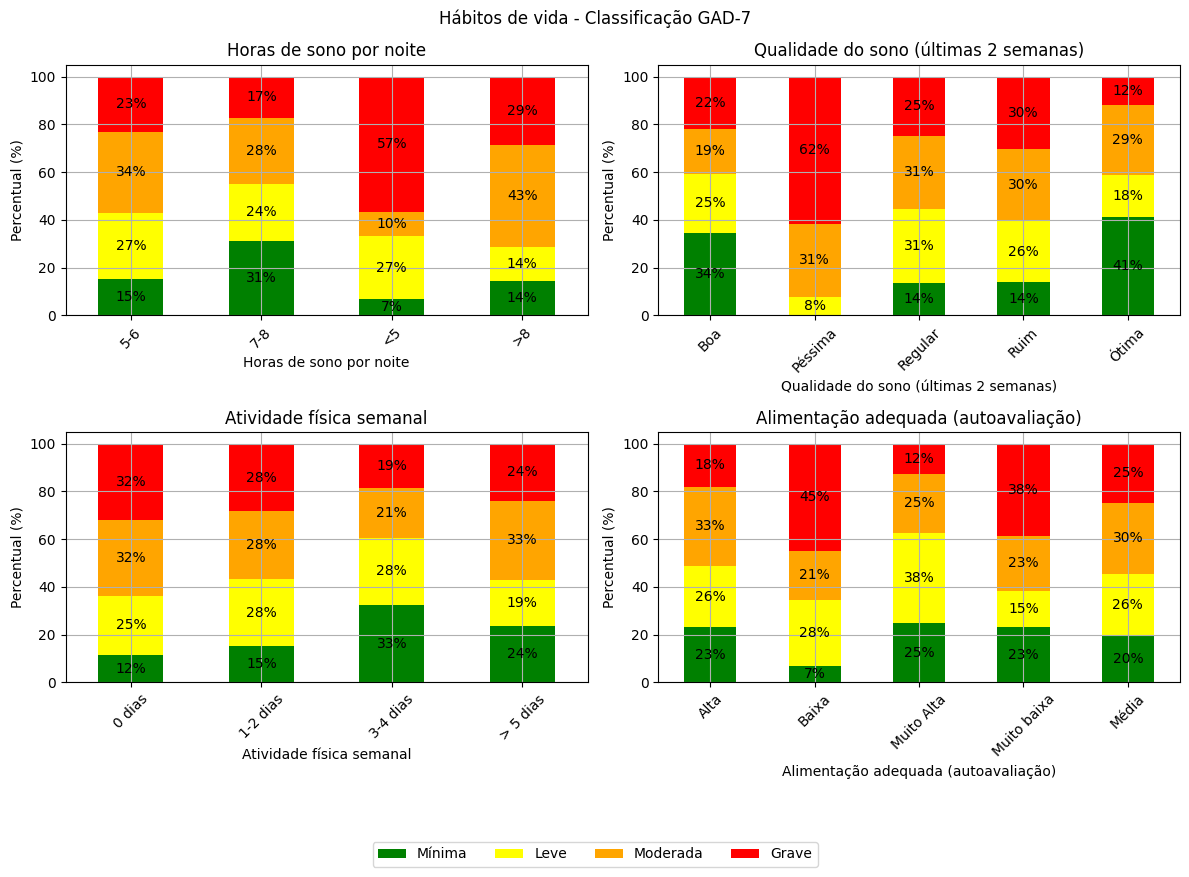

In [ ]:
plt.figure(figsize=(12,8))
plt.suptitle("Hábitos de vida - Classificação GAD-7")

ax_habhsono_cat = plt.subplot(221)
plot_habhsono_cat = pd.crosstab(df['Horas de sono por noite'], df['Nível'], normalize='index') * 100
plot_habhsono_cat.plot(kind='bar', stacked=True, color=nivel_cores, ax=ax_habhsono_cat)
ax_habhsono_cat.set_title("Horas de sono por noite")
ax_habhsono_cat.set_xlabel("Horas de sono por noite")
ax_habhsono_cat.set_ylabel("Percentual (%)")
ax_habhsono_cat.tick_params(axis='x', rotation=45)
ax_habhsono_cat.grid()

ax_habqsono_cat = plt.subplot(222)
plot_habqsono_cat = pd.crosstab(df['Qualidade do sono (últimas 2 semanas)'], df['Nível'], normalize='index') * 100
plot_habqsono_cat.plot(kind='bar',  stacked=True, color=nivel_cores, ax=ax_habqsono_cat)
ax_habqsono_cat.set_title("Qualidade do sono (últimas 2 semanas)")
ax_habqsono_cat.set_xlabel("Qualidade do sono (últimas 2 semanas)")
ax_habqsono_cat.set_ylabel("Percentual (%)")
ax_habqsono_cat.tick_params(axis='x', rotation=45)
ax_habqsono_cat.grid()

ax_habativfis_cat = plt.subplot(223)
plot_habativfis_cat = pd.crosstab(df['Atividade física semanal'], df['Nível'], normalize='index') * 100
plot_habativfis_cat.plot(kind='bar',  stacked=True, color=nivel_cores, ax=ax_habativfis_cat)
ax_habativfis_cat.set_title("Atividade física semanal")
ax_habativfis_cat.set_xlabel("Atividade física semanal")
ax_habativfis_cat.set_ylabel("Percentual (%)")
ax_habativfis_cat.tick_params(axis='x', rotation=45)
ax_habativfis_cat.grid()

ax_habfood_cat = plt.subplot(224)
plot_habfood_bin = pd.crosstab(df['Alimentação adequada (autoavaliação)'], df['Nível'], normalize='index') * 100
plot_habfood_bin.plot(kind='bar',  stacked=True, color=nivel_cores, ax=ax_habfood_cat)
ax_habfood_cat.set_title("Alimentação adequada (autoavaliação)")
ax_habfood_cat.set_xlabel("Alimentação adequada (autoavaliação)")
ax_habfood_cat.set_ylabel("Percentual (%)")
ax_habfood_cat.tick_params(axis='x', rotation=45)
ax_habfood_cat.grid()

ax_habhsono_cat.legend().remove()
ax_habqsono_cat.legend().remove()
ax_habativfis_cat.legend().remove()
ax_habfood_cat.legend().remove()
handles, labels = ax_habhsono_cat.get_legend_handles_labels()
plt.gcf().legend(handles,labels,loc='lower center',ncols=4,bbox_to_anchor=(0.5,-0.1))
add_labels(ax_habhsono_cat)
add_labels(ax_habqsono_cat)
add_labels(ax_habativfis_cat)
add_labels(ax_habfood_cat)
plt.tight_layout()
plt.show()

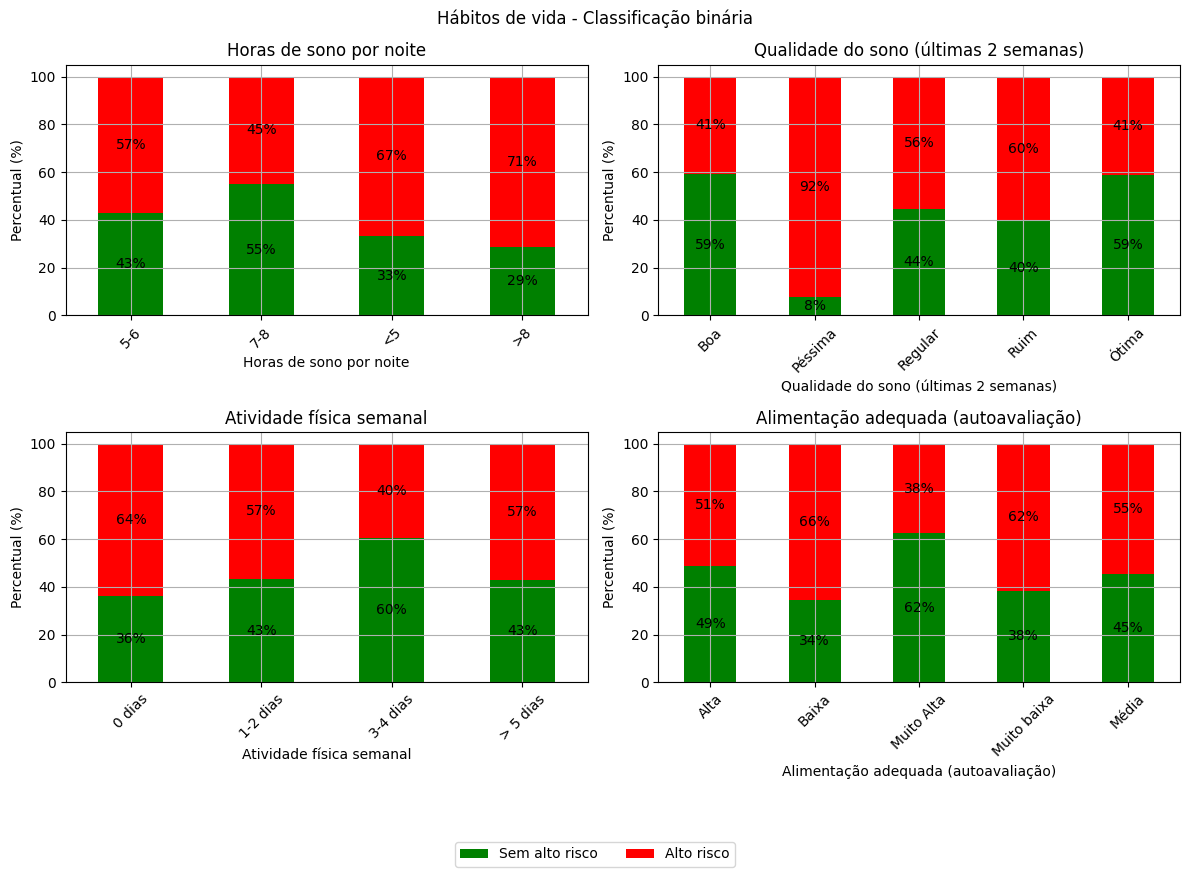

In [ ]:
plt.figure(figsize=(12,8))
plt.suptitle("Hábitos de vida - Classificação binária")

ax_habhsono_bin = plt.subplot(221)
plot_habhsono_bin = pd.crosstab(df['Horas de sono por noite'], df['Ansiedade'], normalize='index') * 100
plot_habhsono_bin = plot_habhsono_bin.rename(columns=ansiedade_rotulos)
plot_habhsono_bin.plot(kind='bar', stacked=True, color=ansiedade_cores, ax=ax_habhsono_bin)
ax_habhsono_bin.set_title("Horas de sono por noite")
ax_habhsono_bin.set_xlabel("Horas de sono por noite")
ax_habhsono_bin.set_ylabel("Percentual (%)")
ax_habhsono_bin.tick_params(axis='x', rotation=45)
ax_habhsono_bin.grid()

ax_habqsono_bin = plt.subplot(222)
plot_habqsono_bin = pd.crosstab(df['Qualidade do sono (últimas 2 semanas)'], df['Ansiedade'], normalize='index') * 100
plot_habqsono_bin = plot_habqsono_bin.rename(columns=ansiedade_rotulos)
plot_habqsono_bin.plot(kind='bar',  stacked=True, color=ansiedade_cores, ax=ax_habqsono_bin)
ax_habqsono_bin.set_title("Qualidade do sono (últimas 2 semanas)")
ax_habqsono_bin.set_xlabel("Qualidade do sono (últimas 2 semanas)")
ax_habqsono_bin.set_ylabel("Percentual (%)")
ax_habqsono_bin.tick_params(axis='x', rotation=45)
ax_habqsono_bin.grid()

ax_habativfis_bin = plt.subplot(223)
plot_habativfis_bin = pd.crosstab(df['Atividade física semanal'], df['Ansiedade'], normalize='index') * 100
plot_habativfis_bin = plot_habativfis_bin.rename(columns=ansiedade_rotulos)
plot_habativfis_bin.plot(kind='bar',  stacked=True, color=ansiedade_cores, ax=ax_habativfis_bin)
ax_habativfis_bin.set_title("Atividade física semanal")
ax_habativfis_bin.set_xlabel("Atividade física semanal")
ax_habativfis_bin.set_ylabel("Percentual (%)")
ax_habativfis_bin.tick_params(axis='x', rotation=45)
ax_habativfis_bin.grid()

ax_habfood_bin = plt.subplot(224)
plot_habfood_bin = pd.crosstab(df['Alimentação adequada (autoavaliação)'], df['Ansiedade'], normalize='index') * 100
plot_habfood_bin = plot_habfood_bin.rename(columns=ansiedade_rotulos)
plot_habfood_bin.plot(kind='bar',  stacked=True, color=ansiedade_cores, ax=ax_habfood_bin)
ax_habfood_bin.set_title("Alimentação adequada (autoavaliação)")
ax_habfood_bin.set_xlabel("Alimentação adequada (autoavaliação)")
ax_habfood_bin.set_ylabel("Percentual (%)")
ax_habfood_bin.tick_params(axis='x', rotation=45)
ax_habfood_bin.grid()

ax_habhsono_bin.legend().remove()
ax_habqsono_bin.legend().remove()
ax_habativfis_bin.legend().remove()
ax_habfood_bin.legend().remove()
handles, labels = ax_habhsono_bin.get_legend_handles_labels()
plt.gcf().legend(handles,labels,loc='lower center',ncols=2,bbox_to_anchor=(0.5,-0.1))
add_labels(ax_habhsono_bin)
add_labels(ax_habqsono_bin)
add_labels(ax_habativfis_bin)
add_labels(ax_habfood_bin)
plt.tight_layout()
plt.show()

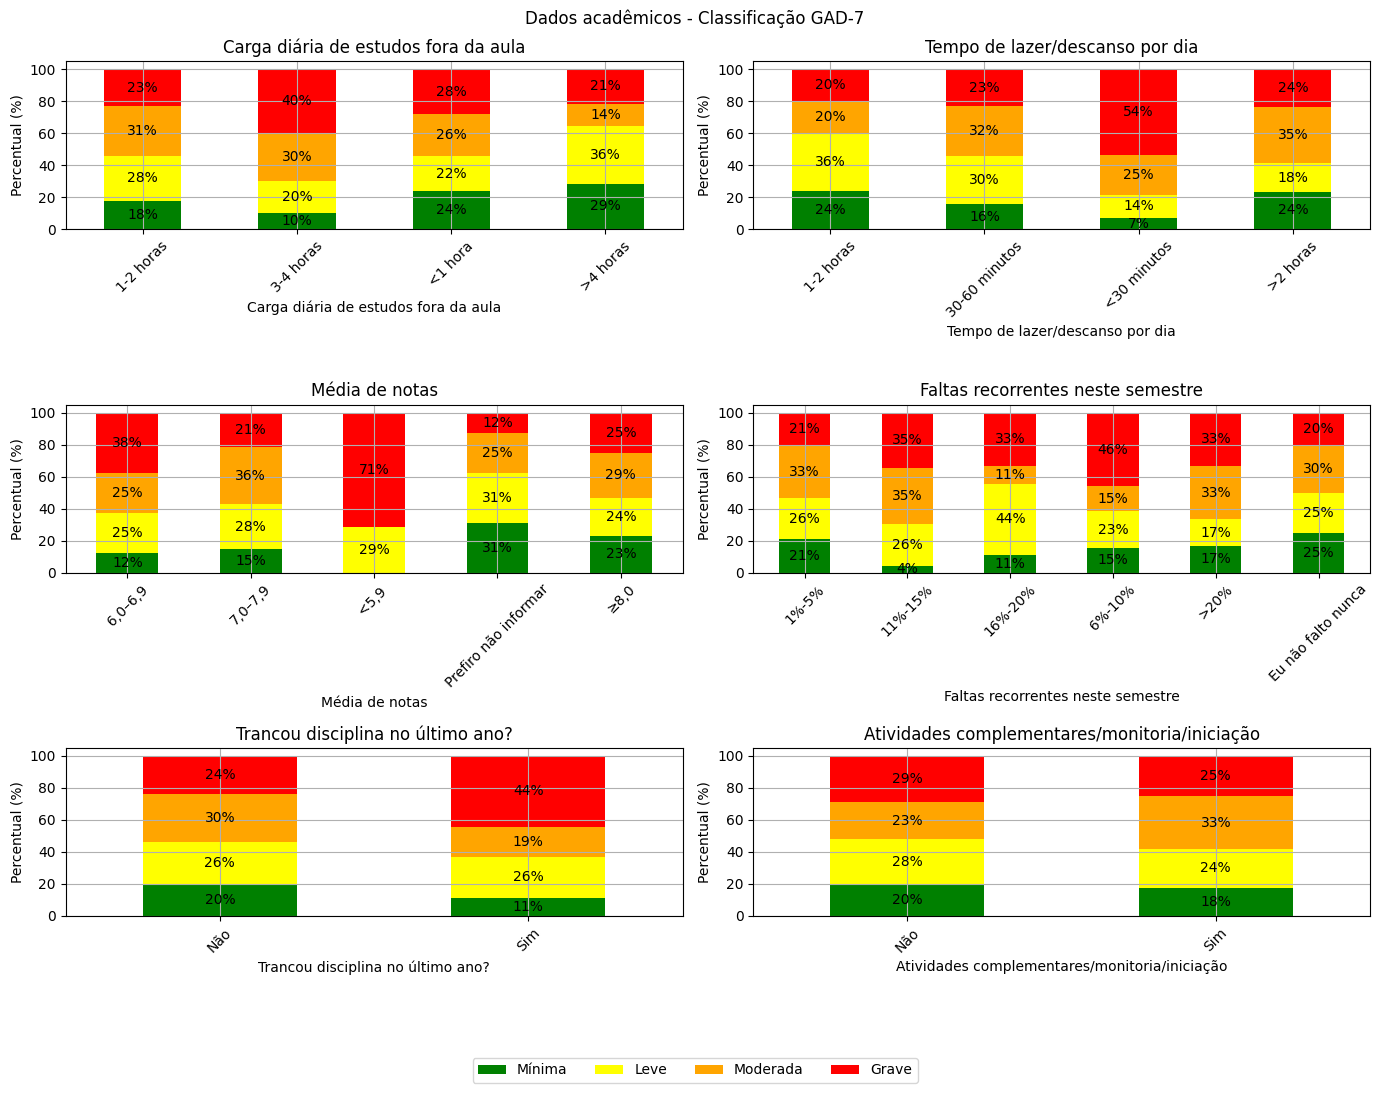

In [ ]:
plt.figure(figsize=(14,10))
plt.suptitle("Dados acadêmicos - Classificação GAD-7")

ax_acadstudy_cat = plt.subplot(321)
plot_acadstudy_cat = pd.crosstab(df['Carga diária de estudos fora da aula'], df['Nível'], normalize='index') * 100
plot_acadstudy_cat.plot(kind='bar', stacked=True, color=nivel_cores, ax=ax_acadstudy_cat)
ax_acadstudy_cat.set_title("Carga diária de estudos fora da aula")
ax_acadstudy_cat.set_xlabel("Carga diária de estudos fora da aula")
ax_acadstudy_cat.set_ylabel("Percentual (%)")
ax_acadstudy_cat.tick_params(axis='x', rotation=45)
ax_acadstudy_cat.grid()

ax_acadlazer_cat = plt.subplot(322)
plot_acadlazer_cat = pd.crosstab(df['Tempo de lazer/descanso por dia'], df['Nível'], normalize='index') * 100
plot_acadlazer_cat.plot(kind='bar',  stacked=True, color=nivel_cores, ax=ax_acadlazer_cat)
ax_acadlazer_cat.set_title("Tempo de lazer/descanso por dia")
ax_acadlazer_cat.set_xlabel("Tempo de lazer/descanso por dia")
ax_acadlazer_cat.set_ylabel("Percentual (%)")
ax_acadlazer_cat.tick_params(axis='x', rotation=45)
ax_acadlazer_cat.grid()

ax_acadnota_cat = plt.subplot(323)
plot_acadnota_bin = pd.crosstab(df['Média de notas'], df['Nível'], normalize='index') * 100
plot_acadnota_bin.plot(kind='bar',  stacked=True, color=nivel_cores, ax=ax_acadnota_cat)
ax_acadnota_cat.set_title("Média de notas")
ax_acadnota_cat.set_xlabel("Média de notas")
ax_acadnota_cat.set_ylabel("Percentual (%)")
ax_acadnota_cat.tick_params(axis='x', rotation=45)
ax_acadnota_cat.grid()

ax_acadfaltas_cat = plt.subplot(324)
plot_acadfaltas_cat = pd.crosstab(df['Faltas recorrentes neste semestre'], df['Nível'], normalize='index') * 100
plot_acadfaltas_cat.plot(kind='bar',  stacked=True, color=nivel_cores, ax=ax_acadfaltas_cat)
ax_acadfaltas_cat.set_title("Faltas recorrentes neste semestre")
ax_acadfaltas_cat.set_xlabel("Faltas recorrentes neste semestre")
ax_acadfaltas_cat.set_ylabel("Percentual (%)")
ax_acadfaltas_cat.tick_params(axis='x', rotation=45)
ax_acadfaltas_cat.grid()

ax_acadtranca_cat = plt.subplot(325)
plot_acadtranca_cat = pd.crosstab(df['Trancou disciplina no último ano?'], df['Nível'], normalize='index') * 100
plot_acadtranca_cat.plot(kind='bar',  stacked=True, color=nivel_cores, ax=ax_acadtranca_cat)
ax_acadtranca_cat.set_title("Trancou disciplina no último ano?")
ax_acadtranca_cat.set_xlabel("Trancou disciplina no último ano?")
ax_acadtranca_cat.set_ylabel("Percentual (%)")
ax_acadtranca_cat.tick_params(axis='x', rotation=45)
ax_acadtranca_cat.grid()

ax_acadhoras_cat = plt.subplot(326)
plot_acadhoras_cat = pd.crosstab(df['Atividades complementares/monitoria/iniciação'], df['Nível'], normalize='index') * 100
plot_acadhoras_cat.plot(kind='bar',  stacked=True, color=nivel_cores, ax=ax_acadhoras_cat)
ax_acadhoras_cat.set_title("Atividades complementares/monitoria/iniciação")
ax_acadhoras_cat.set_xlabel("Atividades complementares/monitoria/iniciação")
ax_acadhoras_cat.set_ylabel("Percentual (%)")
ax_acadhoras_cat.tick_params(axis='x', rotation=45)
ax_acadhoras_cat.grid()

ax_acadstudy_cat.legend().remove()
ax_acadlazer_cat.legend().remove()
ax_acadnota_cat.legend().remove()
ax_acadfaltas_cat.legend().remove()
ax_acadtranca_cat.legend().remove()
ax_acadhoras_cat.legend().remove()
handles, labels = ax_acadstudy_cat.get_legend_handles_labels()
plt.gcf().legend(handles,labels,loc='lower center',ncols=4,bbox_to_anchor=(0.5,-0.1))
add_labels(ax_acadstudy_cat)
add_labels(ax_acadlazer_cat)
add_labels(ax_acadnota_cat)
add_labels(ax_acadfaltas_cat)
add_labels(ax_acadtranca_cat)
add_labels(ax_acadhoras_cat)
plt.tight_layout()
plt.show()

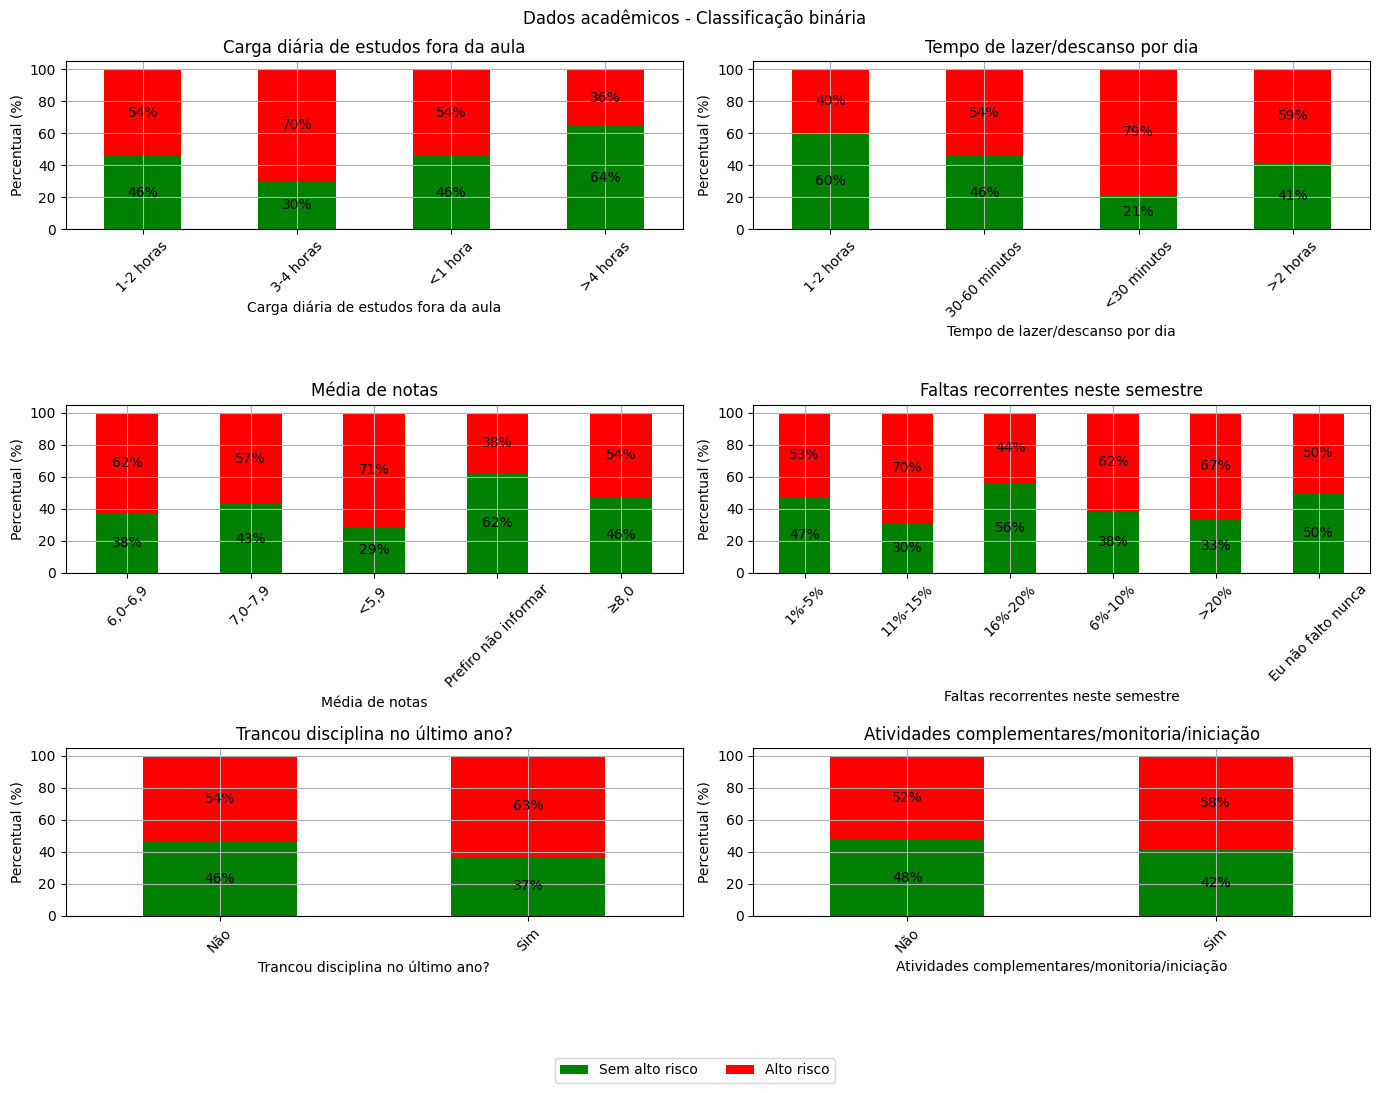

In [ ]:
plt.figure(figsize=(14,10))
plt.suptitle("Dados acadêmicos - Classificação binária")

ax_acadstudy_bin = plt.subplot(321)
plot_acadstudy_bin = pd.crosstab(df['Carga diária de estudos fora da aula'], df['Ansiedade'], normalize='index') * 100
plot_acadstudy_bin = plot_acadstudy_bin.rename(columns=ansiedade_rotulos)
plot_acadstudy_bin.plot(kind='bar', stacked=True, color=ansiedade_cores, ax=ax_acadstudy_bin)
ax_acadstudy_bin.set_title("Carga diária de estudos fora da aula")
ax_acadstudy_bin.set_xlabel("Carga diária de estudos fora da aula")
ax_acadstudy_bin.set_ylabel("Percentual (%)")
ax_acadstudy_bin.tick_params(axis='x', rotation=45)
ax_acadstudy_bin.grid()

ax_acadlazer_bin = plt.subplot(322)
plot_acadlazer_bin = pd.crosstab(df['Tempo de lazer/descanso por dia'], df['Ansiedade'], normalize='index') * 100
plot_acadlazer_bin = plot_acadlazer_bin.rename(columns=ansiedade_rotulos)
plot_acadlazer_bin.plot(kind='bar',  stacked=True, color=ansiedade_cores, ax=ax_acadlazer_bin)
ax_acadlazer_bin.set_title("Tempo de lazer/descanso por dia")
ax_acadlazer_bin.set_xlabel("Tempo de lazer/descanso por dia")
ax_acadlazer_bin.set_ylabel("Percentual (%)")
ax_acadlazer_bin.tick_params(axis='x', rotation=45)
ax_acadlazer_bin.grid()

ax_acadnota_bin = plt.subplot(323)
plot_acadnota_bin = pd.crosstab(df['Média de notas'], df['Ansiedade'], normalize='index') * 100
plot_acadnota_bin = plot_acadnota_bin.rename(columns=ansiedade_rotulos)
plot_acadnota_bin.plot(kind='bar',  stacked=True, color=ansiedade_cores, ax=ax_acadnota_bin)
ax_acadnota_bin.set_title("Média de notas")
ax_acadnota_bin.set_xlabel("Média de notas")
ax_acadnota_bin.set_ylabel("Percentual (%)")
ax_acadnota_bin.tick_params(axis='x', rotation=45)
ax_acadnota_bin.grid()

ax_acadfaltas_bin = plt.subplot(324)
plot_acadfaltas_bin = pd.crosstab(df['Faltas recorrentes neste semestre'], df['Ansiedade'], normalize='index') * 100
plot_acadfaltas_bin = plot_acadfaltas_bin.rename(columns=ansiedade_rotulos)
plot_acadfaltas_bin.plot(kind='bar',  stacked=True, color=ansiedade_cores, ax=ax_acadfaltas_bin)
ax_acadfaltas_bin.set_title("Faltas recorrentes neste semestre")
ax_acadfaltas_bin.set_xlabel("Faltas recorrentes neste semestre")
ax_acadfaltas_bin.set_ylabel("Percentual (%)")
ax_acadfaltas_bin.tick_params(axis='x', rotation=45)
ax_acadfaltas_bin.grid()

ax_acadtranca_bin = plt.subplot(325)
plot_acadtranca_bin = pd.crosstab(df['Trancou disciplina no último ano?'], df['Ansiedade'], normalize='index') * 100
plot_acadtranca_bin = plot_acadtranca_bin.rename(columns=ansiedade_rotulos)
plot_acadtranca_bin.plot(kind='bar',  stacked=True, color=ansiedade_cores, ax=ax_acadtranca_bin)
ax_acadtranca_bin.set_title("Trancou disciplina no último ano?")
ax_acadtranca_bin.set_xlabel("Trancou disciplina no último ano?")
ax_acadtranca_bin.set_ylabel("Percentual (%)")
ax_acadtranca_bin.tick_params(axis='x', rotation=45)
ax_acadtranca_bin.grid()

ax_acadhoras_bin = plt.subplot(326)
plot_acadhoras_bin = pd.crosstab(df['Atividades complementares/monitoria/iniciação'], df['Ansiedade'], normalize='index') * 100
plot_acadhoras_bin = plot_acadhoras_bin.rename(columns=ansiedade_rotulos)
plot_acadhoras_bin.plot(kind='bar',  stacked=True, color=ansiedade_cores, ax=ax_acadhoras_bin)
ax_acadhoras_bin.set_title("Atividades complementares/monitoria/iniciação")
ax_acadhoras_bin.set_xlabel("Atividades complementares/monitoria/iniciação")
ax_acadhoras_bin.set_ylabel("Percentual (%)")
ax_acadhoras_bin.tick_params(axis='x', rotation=45)
ax_acadhoras_bin.grid()

ax_acadstudy_bin.legend().remove()
ax_acadlazer_bin.legend().remove()
ax_acadnota_bin.legend().remove()
ax_acadfaltas_bin.legend().remove()
ax_acadtranca_bin.legend().remove()
ax_acadhoras_bin.legend().remove()
handles, labels = ax_acadstudy_bin.get_legend_handles_labels()
plt.gcf().legend(handles,labels,loc='lower center',ncols=2,bbox_to_anchor=(0.5,-0.1))
add_labels(ax_acadstudy_bin)
add_labels(ax_acadlazer_bin)
add_labels(ax_acadnota_bin)
add_labels(ax_acadfaltas_bin)
add_labels(ax_acadtranca_bin)
add_labels(ax_acadhoras_bin)
plt.tight_layout()
plt.show()

### Análise de fatores individuais associados à ansiedade

Após a caracterização geral da amostra, a análise passa a considerar características próprias de cada estudante, incluindo hábitos de vida, rotina acadêmica e condições relacionadas ao cotidiano universitário.

O objetivo desta etapa é investigar quais características individuais apresentam diferenças no escore GAD-7 e na prevalência de triagem positiva para ansiedade.

As análises são realizadas de forma agregada e anônima, sem identificação individual dos participantes.

In [ ]:
# Fatores relacionados ao contexto individual do estudante
fatores_individuais = [
    'Semestre Atual',
    'Trabalha atualmente?',
    'Horas de sono por noite',
    'Qualidade do sono (últimas 2 semanas)',
    'Atividade física semanal',
    'Alimentação adequada (autoavaliação)',
    'Carga diária de estudos fora da aula',
    'Tempo de lazer/descanso por dia',
    'Média de notas',
    'Faltas recorrentes neste semestre',
    'Trancou disciplina no último ano?',
    'Atividades complementares/monitoria/iniciação'
]

def intervalo_wilson(sucessos, total, alpha=0.05):
    if total == 0:
        return np.nan, np.nan

    z = stats.norm.ppf(1 - alpha / 2)
    p = sucessos / total

    denominador = 1 + z**2 / total
    centro = (p + z**2 / (2 * total)) / denominador
    margem = (
        z
        * np.sqrt(p * (1 - p) / total + z**2 / (4 * total**2))
        / denominador
    )

    return max(0, centro - margem), min(1, centro + margem)


resultados_individuais = []

for fator in fatores_individuais:
    for categoria, grupo in df.groupby(fator):

        if categoria == 'Prefiro não informar':
            continue

        total = len(grupo)

        # Evita interpretar grupos muito pequenos
        if total < 10:
            continue

        alto_risco = int(grupo['Ansiedade'].sum())
        percentual = 100 * alto_risco / total

        ic_inf, ic_sup = intervalo_wilson(alto_risco, total)

        resultados_individuais.append({
            'Fator': fator,
            'Categoria': categoria,
            'n': total,
            'Alto Risco': alto_risco,
            'Percentual de Alto Risco': percentual,
            'IC95% inferior': 100 * ic_inf,
            'IC95% superior': 100 * ic_sup
        })

tabela_risco_individual = pd.DataFrame(resultados_individuais)

tabela_risco_individual = (
    tabela_risco_individual
    .sort_values('Percentual de Alto Risco', ascending=False)
    .reset_index(drop=True)
)

tabela_risco_individual.head(15)

,Fator,Categoria,n,Alto Risco,Percentual de Alto Risco,IC95% inferior,IC95% superior
0,Qualidade do sono (últimas 2 semanas),Péssima,13,12,92.307692,66.686049,98.628958
1,Tempo de lazer/descanso por dia,<30 minutos,28,22,78.571429,60.461414,89.787540
2,Carga diária de estudos fora da aula,3-4 horas,30,21,70.000000,52.124213,83.335252
3,Faltas recorrentes neste semestre,11%-15%,23,16,69.565217,49.134244,84.395976
4,Semestre Atual,5-6,43,29,67.441860,52.516211,79.506703
5,Horas de sono por noite,<5,30,20,66.666667,48.780052,80.769502
6,Alimentação adequada (autoavaliação),Baixa,29,19,65.517241,47.345104,80.059281
7,Atividade física semanal,0 dias,69,44,63.768116,51.979771,74.104276
8,Trancou disciplina no último ano?,Sim,27,17,62.962963,44.229234,78.467487
9,Média de notas,"6,0–6,9",32,20,62.500000,45.254407,77.066113


In [ ]:
MIN_GRUPO = 10
ALPHA = 0.05
SEMENTE = 42
N_PERMUTACOES = 5000

def chave_texto(valor):
    if pd.isna(valor):
        return ''
    texto = unicodedata.normalize('NFKD', str(valor))
    texto = texto.encode('ascii', 'ignore').decode('ascii').lower().strip()
    return re.sub(r'\s+', ' ', texto)

def padronizado_curso(valor):
    chave = chave_texto(valor)
    if 'ciencia da computacao' in chave or 'sistemas de informacao' in chave:
        return 'Ciência da Computação/Sistemas de Informação'
    if chave == 'ads' or ('analise' in chave and 'desenvolvimento' in chave and 'sistema' in chave):
        return 'Análise e Desenvolvimento de Sistemas'
    if 'banco de dados' in chave or 'ciencia/banco de dados' in chave:
        return 'Banco de Dados'
    if 'licenciatura em matematica' in chave:
        return 'Licenciatura em Matemática'
    if 'direito' in chave:
        return 'Direito'
    if chave == 'pp' or 'publicidade' in chave:
        return 'Publicidade e Propaganda'
    if 'engenharia de gestao' in chave:
        return 'Engenharia de Gestão'
    return str(valor).strip() if chave else 'Não informado'

def derivar_faculdade(curso):
    if curso in {
        'Ciência da Computação/Sistemas de Informação',
        'Análise e Desenvolvimento de Sistemas',
        'Banco de Dados',
        'Licenciatura em Matemática'
    }:
        return 'FCI'
    if curso == 'Direito':
        return 'FDIR'
    if curso == 'Publicidade e Propaganda':
        return 'CCL'
    if curso == 'Engenharia de Gestão':
        return 'Escola de Engenharia'
    return 'Não determinada'

### Associação entre fatores individuais e ansiedade

Além das diferenças observadas visualmente entre as categorias, foram realizados testes estatísticos para avaliar se as distribuições do escore GAD-7 e da classificação binária diferem de maneira significativa entre os grupos definidos pelas características individuais.

Para o escore GAD-7 foram empregados testes não paramétricos, reduzindo a dependência de pressupostos de normalidade. Para a classificação de alto risco foram utilizados testes de associação entre variáveis categóricas.

Categorias com menos de 10 participantes foram excluídas das comparações inferenciais devido à maior instabilidade das estimativas.

In [ ]:
MIN_GRUPO = 10
ALPHA = 0.05


def corrigir_bh(valores_p):
    valores = np.asarray(valores_p, dtype=float)

    ajustados = np.full(valores.shape, np.nan)
    validos = np.isfinite(valores)

    if not validos.any():
        return ajustados

    p = valores[validos]

    ordem = np.argsort(p)
    ordenados = p[ordem]

    m = len(ordenados)

    bh = ordenados * m / np.arange(1, m + 1)
    bh = np.minimum.accumulate(bh[::-1])[::-1]
    bh = np.clip(bh, 0, 1)

    retorno = np.empty(m)
    retorno[ordem] = bh

    ajustados[np.where(validos)[0]] = retorno

    return ajustados


def cramers_v(tabela):
    chi2, _, _, _ = stats.chi2_contingency(tabela)

    n = tabela.to_numpy().sum()
    linhas, colunas = tabela.shape

    denominador = min(linhas - 1, colunas - 1)

    if denominador == 0:
        return np.nan

    return np.sqrt(chi2 / (n * denominador))


def analisar_fator_individual(df, fator):

    base = df[
        [fator, 'Score GAD-7', 'Ansiedade']
    ].dropna().copy()

    base = base[
        base[fator] != 'Prefiro não informar'
    ]

    contagens = base[fator].value_counts()

    categorias_validas = contagens[
        contagens >= MIN_GRUPO
    ].index

    base = base[
        base[fator].isin(categorias_validas)
    ]

    categorias = list(base[fator].unique())

    if len(categorias) < 2:
        return None

    amostras = [
        base.loc[
            base[fator] == categoria,
            'Score GAD-7'
        ].to_numpy()
        for categoria in categorias
    ]

    # Escore GAD-7
    if len(categorias) == 2:

        resultado_score = stats.mannwhitneyu(
            amostras[0],
            amostras[1],
            alternative='two-sided'
        )

        teste_score = 'Mann-Whitney'

        n1 = len(amostras[0])
        n2 = len(amostras[1])

        efeito_score = abs(
            2 * resultado_score.statistic / (n1 * n2) - 1
        )

        medida_efeito = '|r bisserial|'

    else:

        resultado_score = stats.kruskal(*amostras)

        teste_score = 'Kruskal-Wallis'

        n = sum(len(a) for a in amostras)
        k = len(amostras)

        efeito_score = max(
            0,
            (resultado_score.statistic - k + 1) / (n - k)
        )

        medida_efeito = 'Epsilon²'

    # Triagem positiva
    tabela = pd.crosstab(
        base[fator],
        base['Ansiedade']
    )

    chi2, p_triagem, _, _ = stats.chi2_contingency(tabela)

    return {
        'Fator': fator,
        'n': len(base),

        'Teste GAD-7': teste_score,
        'p GAD-7': resultado_score.pvalue,
        'Medida efeito GAD-7': medida_efeito,
        'Efeito GAD-7': efeito_score,

        'Teste triagem': 'Qui-quadrado',
        'p triagem': p_triagem,
        "Cramér's V": cramers_v(tabela)
    }


resultados_associacao = []

for fator in fatores_individuais:

    resultado = analisar_fator_individual(
        df,
        fator
    )

    if resultado is not None:
        resultados_associacao.append(resultado)


tabela_associacoes = pd.DataFrame(
    resultados_associacao
)

# Correção para múltiplas comparações
tabela_associacoes['p GAD-7 ajustado'] = corrigir_bh(
    tabela_associacoes['p GAD-7']
)

tabela_associacoes['p triagem ajustado'] = corrigir_bh(
    tabela_associacoes['p triagem']
)

tabela_associacoes['Significativo GAD-7'] = (
    tabela_associacoes['p GAD-7 ajustado'] < ALPHA
)

tabela_associacoes['Significativo triagem'] = (
    tabela_associacoes['p triagem ajustado'] < ALPHA
)

tabela_associacoes.sort_values(
    'p triagem ajustado'
)

,Fator,n,Teste GAD-7,p GAD-7,Medida efeito GAD-7,Efeito GAD-7,Teste triagem,p triagem,Cramér's V,p GAD-7 ajustado,p triagem ajustado,Significativo GAD-7,Significativo triagem
3,Qualidade do sono (últimas 2 semanas),186,Kruskal-Wallis,0.000235,Epsilon²,0.097537,Qui-quadrado,0.018645,0.252217,0.002095,0.111867,True,False
7,Tempo de lazer/descanso por dia,186,Kruskal-Wallis,0.025184,Epsilon²,0.034793,Qui-quadrado,0.010952,0.244818,0.075551,0.111867,False,False
2,Horas de sono por noite,179,Kruskal-Wallis,0.000349,Epsilon²,0.079088,Qui-quadrado,0.120342,0.153813,0.002095,0.315791,True,False
0,Semestre Atual,178,Kruskal-Wallis,0.060623,Epsilon²,0.025194,Qui-quadrado,0.131580,0.177703,0.103926,0.315791,False,False
4,Atividade física semanal,186,Kruskal-Wallis,0.024345,Epsilon²,0.035202,Qui-quadrado,0.094017,0.185381,0.075551,0.315791,False,False
6,Carga diária de estudos fora da aula,186,Kruskal-Wallis,0.224198,Epsilon²,0.007527,Qui-quadrado,0.182105,0.161695,0.279213,0.364211,False,False
1,Trabalha atualmente?,180,Kruskal-Wallis,0.232677,Epsilon²,0.005176,Qui-quadrado,0.360975,0.106403,0.279213,0.562574,False,False
9,Faltas recorrentes neste semestre,171,Kruskal-Wallis,0.059643,Epsilon²,0.026469,Qui-quadrado,0.375049,0.134849,0.103926,0.562574,False,False
11,Atividades complementares/monitoria/iniciação,186,Mann-Whitney,0.532798,|r bisserial|,0.053009,Qui-quadrado,0.490012,0.050614,0.532798,0.620109,False,False
10,Trancou disciplina no último ano?,186,Mann-Whitney,0.059046,|r bisserial|,0.227347,Qui-quadrado,0.516757,0.047539,0.103926,0.620109,False,False


### Modelo multivariado de fatores individuais

Com o objetivo de avaliar simultaneamente diferentes características do estudante, foi ajustado um modelo multivariado utilizando fatores relacionados à rotina acadêmica e aos hábitos de vida.

Essa abordagem permite avaliar a associação de cada característica com o desfecho considerando as demais variáveis presentes no modelo, reduzindo a influência de possíveis fatores de confusão.

O modelo não possui finalidade diagnóstica individual, sendo utilizado exclusivamente para investigação estatística das associações observadas na amostra.

In [ ]:
base_individual = df.copy()

# Semestre
base_individual['semestre_ord'] = base_individual[
    'Semestre Atual'
].map({
    '1-2': 1.5,
    '3-4': 3.5,
    '5-6': 5.5,
    '7-8': 7.5,
    '9+': 9
})

# Horas de sono
base_individual['horas_sono_ord'] = base_individual[
    'Horas de sono por noite'
].map({
    '<5': 4.5,
    '5-6': 5.5,
    '7-8': 7.5,
    '>8': 9
})

# Qualidade de sono
base_individual['qualidade_sono_ord'] = base_individual[
    'Qualidade do sono (últimas 2 semanas)'
].map({
    'Péssima': 1,
    'Ruim': 2,
    'Regular': 3,
    'Boa': 4,
    'Ótima': 5
})

# Atividade física
base_individual['atividade_ord'] = base_individual[
    'Atividade física semanal'
].map({
    '0 dias': 0,
    '1-2 dias': 1.5,
    '3-4 dias': 3.5,
    '> 5 dias': 6
})

# Alimentação
base_individual['alimentacao_ord'] = base_individual[
    'Alimentação adequada (autoavaliação)'
].map({
    'Muito baixa': 1,
    'Baixa': 2,
    'Média': 3,
    'Alta': 4,
    'Muito Alta': 5
})

# Horas de estudo
base_individual['estudos_ord'] = base_individual[
    'Carga diária de estudos fora da aula'
].map({
    '<1 hora': 0.5,
    '1-2 horas': 1.5,
    '3-4 horas': 3.5,
    '>4 horas': 5
})

# Lazer
base_individual['lazer_ord'] = base_individual[
    'Tempo de lazer/descanso por dia'
].map({
    '<30 minutos': 0.25,
    '30-60 minutos': 0.75,
    '1-2 horas': 1.5,
    '>2 horas': 2.5
})

# Trabalho
base_individual['trabalha_bin'] = base_individual[
    'Trabalha atualmente?'
].map({
    'Não': 0,
    'Sim, meio período': 1,
    'Sim, integral': 1
})

# Trancamento
base_individual['trancou_bin'] = base_individual[
    'Trancou disciplina no último ano?'
].map({
    'Não': 0,
    'Sim': 1
})

# Atividades acadêmicas extras
base_individual['atividades_bin'] = base_individual[
    'Atividades complementares/monitoria/iniciação'
].map({
    'Não': 0,
    'Sim': 1
})

base_individual['score_gad7'] = base_individual[
    'Score GAD-7'
]

base_individual['triagem_positiva'] = base_individual[
    'Ansiedade'
]

In [ ]:
formula_individual = (
    'score_gad7 ~ '
    'semestre_ord + '
    'trabalha_bin + '
    'horas_sono_ord + '
    'qualidade_sono_ord + '
    'atividade_ord + '
    'alimentacao_ord + '
    'estudos_ord + '
    'lazer_ord + '
    'trancou_bin + '
    'atividades_bin'
)

modelo_gad_individual = smf.ols(
    formula_individual,
    data=base_individual
).fit(cov_type='HC3')

modelo_gad_individual.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:             score_gad7   R-squared:                       0.176
Model:                            OLS   Adj. R-squared:                  0.126
Method:                 Least Squares   F-statistic:                     3.390
Date:                Sun, 08 Nov 2026   Prob (F-statistic):           0.000479
Time:                        15:27:51   Log-Likelihood:                -531.22
No. Observations:                 174   AIC:                             1084.
Df Residuals:                     163   BIC:                             1119.
Df Model:                          10                                         
Covariance Type:                  HC3                                         
======================================================================================
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept             18.0854      2.877      6.286      0.000      12.446      23.725
semestre_ord           0.1749      0.207      0.846      0.398      -0.230       0.580
trabalha_bin          -1.4044      1.085     -1.294      0.196      -3.531       0.722
horas_sono_ord        -0.3298      0.436     -0.757      0.449      -1.184       0.524
qualidade_sono_ord    -1.3726      0.474     -2.895      0.004      -2.302      -0.443
atividade_ord         -0.3574      0.241     -1.486      0.137      -0.829       0.114
alimentacao_ord       -0.3355      0.518     -0.648      0.517      -1.351       0.680
estudos_ord            0.1397      0.366      0.381      0.703      -0.579       0.858
lazer_ord             -0.5316      0.604     -0.880      0.379      -1.716       0.652
trancou_bin            1.6304      1.284      1.270      0.204      -0.887       4.147
atividades_bin         0.6851      0.890      0.770      0.441      -1.059       2.430
==============================================================================
Omnibus:                       16.900   Durbin-Watson:                   2.394
Prob(Omnibus):                  0.000   Jarque-Bera (JB):                5.705
Skew:                           0.051   Prob(JB):                       0.0577
Kurtosis:                       2.119   Cond. No.                         61.5
==============================================================================

Notes:
[1] Standard Errors are heteroscedasticity robust (HC3)
"""

In [ ]:
formula_triagem_individual = (
    'triagem_positiva ~ '
    'semestre_ord + '
    'trabalha_bin + '
    'horas_sono_ord + '
    'qualidade_sono_ord + '
    'atividade_ord + '
    'alimentacao_ord + '
    'estudos_ord + '
    'lazer_ord + '
    'trancou_bin + '
    'atividades_bin'
)

modelo_triagem_individual = smf.glm(
    formula_triagem_individual,
    data=base_individual,
    family=sm.families.Poisson()
).fit(cov_type='HC3')

modelo_triagem_individual.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                 Generalized Linear Model Regression Results                  
==============================================================================
Dep. Variable:       triagem_positiva   No. Observations:                  174
Model:                            GLM   Df Residuals:                      163
Model Family:                 Poisson   Df Model:                           10
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -148.12
Date:                Sun, 08 Nov 2026   Deviance:                       110.24
Time:                        15:27:51   Pearson chi2:                     80.4
No. Iterations:                     5   Pseudo R-squ. (CS):            0.03543
Covariance Type:                  HC3                                         
======================================================================================
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept              0.1373      0.461      0.298      0.766      -0.766       1.040
semestre_ord           0.0125      0.034      0.371      0.711      -0.054       0.078
trabalha_bin          -0.0867      0.175     -0.494      0.621      -0.431       0.257
horas_sono_ord        -0.0117      0.074     -0.157      0.875      -0.158       0.134
qualidade_sono_ord    -0.1811      0.078     -2.334      0.020      -0.333      -0.029
atividade_ord         -0.0322      0.041     -0.790      0.430      -0.112       0.048
alimentacao_ord       -0.0575      0.082     -0.698      0.485      -0.219       0.104
estudos_ord            0.0125      0.055      0.228      0.820      -0.095       0.120
lazer_ord             -0.0490      0.103     -0.475      0.635      -0.251       0.153
trancou_bin            0.1398      0.171      0.819      0.413      -0.195       0.474
atividades_bin         0.1589      0.147      1.080      0.280      -0.129       0.447
======================================================================================
"""

In [ ]:
coef = modelo_triagem_individual.params
ic = modelo_triagem_individual.conf_int()

tabela_rp_individual = pd.DataFrame({
    'Fator': coef.index,
    'RP ajustada': np.exp(coef),
    'IC95% inferior': np.exp(ic[0]),
    'IC95% superior': np.exp(ic[1]),
    'p-valor': modelo_triagem_individual.pvalues
})

tabela_rp_individual = (
    tabela_rp_individual
    .drop(index='Intercept')
    .sort_values('p-valor')
)

tabela_rp_individual

,Fator,RP ajustada,IC95% inferior,IC95% superior,p-valor
qualidade_sono_ord,qualidade_sono_ord,0.834318,0.716583,0.971396,0.019602
atividades_bin,atividades_bin,1.172268,0.878596,1.564100,0.280023
trancou_bin,trancou_bin,1.150013,0.823100,1.606767,0.412727
atividade_ord,atividade_ord,0.968280,0.893850,1.048908,0.429597
alimentacao_ord,alimentacao_ord,0.944169,0.803452,1.109532,0.485366
trabalha_bin,trabalha_bin,0.916920,0.650054,1.293341,0.621142
lazer_ord,lazer_ord,0.952223,0.778080,1.165340,0.634726
semestre_ord,semestre_ord,1.012571,0.947901,1.081653,0.710642
estudos_ord,estudos_ord,1.012588,0.909264,1.127654,0.819798
horas_sono_ord,horas_sono_ord,0.988388,0.854118,1.143766,0.875414


In [ ]:
# Reutiliza integralmente o pré-processamento e o GAD-7 calculados acima.
# A consulta à base bruta recupera somente o curso original, perdido no agrupamento anterior.
cursos_originais = (
    df_raw[['ID', 'Curso/Faculdade']]
    .rename(columns={'Curso/Faculdade': 'curso_original'})
)
if cursos_originais['ID'].duplicated().any() or df['ID'].duplicated().any():
    raise ValueError('O ID deve ser único para relacionar a base tratada ao curso original.')

analise_gad = df.merge(cursos_originais, on='ID', how='left', validate='one_to_one').copy()
if analise_gad['curso_original'].isna().any():
    raise ValueError('Há participantes da base tratada sem curso correspondente na base original.')

analise_gad['curso'] = analise_gad['curso_original'].apply(padronizado_curso)
analise_gad['faculdade'] = analise_gad['curso'].apply(derivar_faculdade)
analise_gad['modalidade'] = np.where(
    analise_gad['Campus'].apply(chave_texto).eq('ead'), 'EaD', 'Presencial'
)
analise_gad['turno'] = analise_gad['Turno'].str.strip()
analise_gad['score_gad7'] = analise_gad['Score GAD-7']
analise_gad['nivel_gad7'] = analise_gad['Nível']
analise_gad['triagem_positiva'] = analise_gad['Ansiedade']
ORDEM_NIVEIS = list(analise_gad['nivel_gad7'].cat.categories)

display(pd.DataFrame([{
    'Participantes reutilizados': len(analise_gad),
    'IDs sem curso original': int(analise_gad['curso_original'].isna().sum())
}]))

,Participantes reutilizados,IDs sem curso original
0,186,0


In [ ]:
def corrigir_bh(valores_p):
    valores = np.asarray(valores_p, dtype=float)
    ajustados = np.full(valores.shape, np.nan)
    validos = np.isfinite(valores)
    if not validos.any():
        return ajustados
    p = valores[validos]
    ordem = np.argsort(p)
    ordenados = p[ordem]
    m = len(ordenados)
    bh = ordenados * m / np.arange(1, m + 1)
    bh = np.minimum.accumulate(bh[::-1])[::-1]
    bh = np.clip(bh, 0, 1)
    retorno = np.empty(m)
    retorno[ordem] = bh
    ajustados[np.where(validos)[0]] = retorno
    return ajustados

def grupos_elegiveis(dados, dimensao):
    base = dados.loc[dados[dimensao].notna()].copy()
    base = base.loc[~base[dimensao].isin(['Não informado', 'Não determinada', 'Não determinado'])]
    if dimensao == 'turno':
        base = base.loc[base['turno'].isin(['Matutino', 'Noturno'])]
    contagens = base[dimensao].value_counts()
    elegiveis = contagens.loc[contagens.ge(MIN_GRUPO)].index
    return base.loc[base[dimensao].isin(elegiveis)].copy(), contagens

def intervalo_wilson(sucessos, total, alpha=ALPHA):
    if total == 0:
        return np.nan, np.nan
    z = stats.norm.ppf(1 - alpha / 2)
    proporcao = sucessos / total
    denominador = 1 + z ** 2 / total
    centro = (proporcao + z ** 2 / (2 * total)) / denominador
    margem = z * np.sqrt(
        proporcao * (1 - proporcao) / total + z ** 2 / (4 * total ** 2)
    ) / denominador
    return max(0, centro - margem), min(1, centro + margem)

def resumo_dimensao(dados, dimensao):
    base, contagens = grupos_elegiveis(dados, dimensao)
    linhas = []
    for grupo, recorte in base.groupby(dimensao, observed=True):
        n = len(recorte)
        positivos = int(recorte['triagem_positiva'].sum())
        inferior, superior = intervalo_wilson(positivos, n)
        linhas.append({
            dimensao: grupo,
            'n': n,
            'media_gad7': recorte['score_gad7'].mean(),
            'desvio_padrao': recorte['score_gad7'].std(),
            'mediana_gad7': recorte['score_gad7'].median(),
            'q1': recorte['score_gad7'].quantile(0.25),
            'q3': recorte['score_gad7'].quantile(0.75),
            'triagem_positiva_n': positivos,
            'triagem_positiva_pct': 100 * positivos / n,
            'ic95_inferior_pct': 100 * inferior,
            'ic95_superior_pct': 100 * superior
        })
    return pd.DataFrame(linhas), contagens

def tamanho_efeito_hedges(x, y):
    n1, n2 = len(x), len(y)
    variancia_agrupada = ((n1 - 1) * np.var(x, ddof=1) + (n2 - 1) * np.var(y, ddof=1)) / (n1 + n2 - 2)
    if variancia_agrupada <= 0:
        return 0.0
    d = (np.mean(x) - np.mean(y)) / np.sqrt(variancia_agrupada)
    correcao = 1 - 3 / (4 * (n1 + n2) - 9)
    return d * correcao

def anova_welch(amostras):
    quantidades = np.asarray([len(amostra) for amostra in amostras], dtype=float)
    medias = np.asarray([np.mean(amostra) for amostra in amostras], dtype=float)
    variancias = np.asarray([np.var(amostra, ddof=1) for amostra in amostras], dtype=float)
    if np.any(variancias <= 0):
        raise ValueError('A ANOVA de Welch requer variância positiva em todos os grupos.')
    pesos = quantidades / variancias
    soma_pesos = pesos.sum()
    media_ponderada = np.sum(pesos * medias) / soma_pesos
    k = len(amostras)
    termo = np.sum((1 - pesos / soma_pesos) ** 2 / (quantidades - 1))
    numerador = np.sum(pesos * (medias - media_ponderada) ** 2) / (k - 1)
    correcao = 1 + (2 * (k - 2) / (k ** 2 - 1)) * termo
    estatistica = numerador / correcao
    gl1 = k - 1
    gl2 = (k ** 2 - 1) / (3 * termo)
    return estatistica, stats.f.sf(estatistica, gl1, gl2), gl1, gl2

def teste_score(dados, dimensao):
    base, _ = grupos_elegiveis(dados, dimensao)
    grupos = sorted(base[dimensao].unique())
    if len(grupos) < 2:
        return pd.DataFrame([{'dimensao': dimensao, 'desfecho': 'score_gad7', 'metodo': 'Amostra insuficiente'}])
    amostras = [base.loc[base[dimensao].eq(grupo), 'score_gad7'].to_numpy() for grupo in grupos]
    normalidade = all(len(amostra) >= 3 and stats.shapiro(amostra).pvalue >= ALPHA for amostra in amostras)
    linhas = []
    if len(grupos) == 2:
        if normalidade:
            resultado = stats.ttest_ind(amostras[0], amostras[1], equal_var=False)
            metodo = 't de Welch'
            efeito = tamanho_efeito_hedges(amostras[0], amostras[1])
            nome_efeito = 'g de Hedges'
        else:
            resultado = stats.mannwhitneyu(amostras[0], amostras[1], alternative='two-sided')
            metodo = 'Mann-Whitney'
            efeito = 2 * resultado.statistic / (len(amostras[0]) * len(amostras[1])) - 1
            nome_efeito = 'correlação bisserial de postos'
        linhas.append({
            'dimensao': dimensao, 'desfecho': 'score_gad7',
            'comparacao': f'{grupos[0]} × {grupos[1]}',
            'metodo': metodo, 'estatistica': resultado.statistic,
            'p_valor': resultado.pvalue, 'efeito': efeito, 'medida_efeito': nome_efeito
        })
        return pd.DataFrame(linhas)
    if normalidade:
        estatistica_global, p_global, _, _ = anova_welch(amostras)
        metodo_global = 'ANOVA de Welch'
    else:
        global_resultado = stats.kruskal(*amostras)
        estatistica_global, p_global = global_resultado.statistic, global_resultado.pvalue
        metodo_global = 'Kruskal-Wallis'
    linhas.append({
        'dimensao': dimensao, 'desfecho': 'score_gad7', 'comparacao': 'Global',
        'metodo': metodo_global, 'estatistica': estatistica_global,
        'p_valor': p_global
    })
    pares = []
    for grupo_a, grupo_b in combinations(grupos, 2):
        x = base.loc[base[dimensao].eq(grupo_a), 'score_gad7'].to_numpy()
        y = base.loc[base[dimensao].eq(grupo_b), 'score_gad7'].to_numpy()
        if normalidade:
            resultado = stats.ttest_ind(x, y, equal_var=False)
            efeito = tamanho_efeito_hedges(x, y)
            metodo = 't de Welch (pós-teste)'
            medida = 'g de Hedges'
        else:
            resultado = stats.mannwhitneyu(x, y, alternative='two-sided')
            efeito = 2 * resultado.statistic / (len(x) * len(y)) - 1
            metodo = 'Mann-Whitney (pós-teste)'
            medida = 'correlação bisserial de postos'
        pares.append({
            'dimensao': dimensao, 'desfecho': 'score_gad7',
            'comparacao': f'{grupo_a} × {grupo_b}', 'metodo': metodo,
            'estatistica': resultado.statistic, 'p_valor': resultado.pvalue,
            'efeito': efeito, 'medida_efeito': medida
        })
    if pares:
        p_ajustados = corrigir_bh([linha['p_valor'] for linha in pares])
        for linha, p_ajustado in zip(pares, p_ajustados):
            linha['p_pos_teste_bh'] = p_ajustado
    return pd.DataFrame(linhas + pares)

def estatistica_qui_quadrado(tabela):
    observado = np.asarray(tabela, dtype=float)
    total = observado.sum()
    esperado = observado.sum(axis=1, keepdims=True) @ observado.sum(axis=0, keepdims=True) / total
    return np.sum(np.divide((observado - esperado) ** 2, esperado, out=np.zeros_like(observado), where=esperado > 0))

def p_permutacao_categorica(base, dimensao, desfecho, tabela, repeticoes=N_PERMUTACOES):
    categorias_grupo = list(tabela.index)
    categorias_desfecho = list(tabela.columns)
    codigos_grupo = pd.Categorical(base[dimensao], categories=categorias_grupo).codes
    codigos_desfecho = pd.Categorical(base[desfecho], categories=categorias_desfecho).codes
    observado = estatistica_qui_quadrado(tabela.to_numpy())
    rng = np.random.default_rng(SEMENTE)
    extremos = 0
    for _ in range(repeticoes):
        permutados = rng.permutation(codigos_grupo)
        simulada = np.zeros(tabela.shape, dtype=int)
        np.add.at(simulada, (permutados, codigos_desfecho), 1)
        extremos += estatistica_qui_quadrado(simulada) >= observado - 1e-12
    return (extremos + 1) / (repeticoes + 1)

def teste_categorico(dados, dimensao, desfecho):
    base, _ = grupos_elegiveis(dados, dimensao)
    tabela = pd.crosstab(base[dimensao], base[desfecho])
    if tabela.shape[0] < 2 or tabela.shape[1] < 2:
        return pd.DataFrame([{'dimensao': dimensao, 'desfecho': desfecho, 'metodo': 'Amostra insuficiente'}])
    qui2, p_assintotico, graus, esperadas = stats.chi2_contingency(tabela)
    usar_permutacao = (esperadas < 5).mean() > 0.20 or esperadas.min() < 1
    if usar_permutacao:
        p_valor = p_permutacao_categorica(base, dimensao, desfecho, tabela)
        metodo = f'Qui-quadrado com {N_PERMUTACOES} permutações'
    else:
        p_valor = p_assintotico
        metodo = 'Qui-quadrado de Pearson'
    denominador = len(base) * min(tabela.shape[0] - 1, tabela.shape[1] - 1)
    cramers_v = np.sqrt(qui2 / denominador) if denominador > 0 else np.nan
    return pd.DataFrame([{
        'dimensao': dimensao, 'desfecho': desfecho, 'comparacao': 'Global',
        'metodo': metodo, 'estatistica': qui2, 'p_valor': p_valor,
        'efeito': cramers_v, 'medida_efeito': 'V de Cramér'
    }])

In [ ]:
CORES_NIVEIS = {
    'Mínima': '#2E8B57',
    'Leve': '#F1C40F',
    'Moderada': '#E67E22',
    'Grave': '#C0392B'
}

def plotar_dimensao(dados, dimensao):
    base, _ = grupos_elegiveis(dados, dimensao)
    ordem = list(base[dimensao].value_counts().index)
    if len(ordem) < 2:
        print(f'{dimensao}: não há dois grupos elegíveis para comparação.')
        return
    rotulos = [textwrap.fill(str(valor), 22) for valor in ordem]
    figura, eixos = plt.subplots(1, 3, figsize=(19, 6))

    sns.boxplot(data=base, x=dimensao, y='score_gad7', order=ordem, ax=eixos[0], color='#8EC5E8')
    sns.stripplot(data=base, x=dimensao, y='score_gad7', order=ordem, ax=eixos[0], color='#1F3A5F', alpha=0.35, size=3)
    eixos[0].set_title('Distribuição do escore GAD-7')
    eixos[0].set_xlabel('')
    eixos[0].set_ylabel('Escore GAD-7 (0–21)')
    eixos[0].set_xticks(range(len(ordem)), rotulos, rotation=15, ha='right')

    proporcoes = pd.crosstab(base[dimensao], base['nivel_gad7'], normalize='index')
    proporcoes = proporcoes.reindex(index=ordem, columns=ORDEM_NIVEIS, fill_value=0) * 100
    proporcoes.plot(
        kind='bar', stacked=True, ax=eixos[1],
        color=[CORES_NIVEIS[nivel] for nivel in ORDEM_NIVEIS]
    )
    eixos[1].set_title('Composição percentual dos níveis')
    eixos[1].set_xlabel('')
    eixos[1].set_ylabel('Participantes (%)')
    eixos[1].set_xticks(range(len(ordem)), rotulos, rotation=15, ha='right')
    eixos[1].legend(title='Nível GAD-7', fontsize=8)

    resumo, _ = resumo_dimensao(base, dimensao)
    resumo = resumo.set_index(dimensao).reindex(ordem).reset_index()
    y = resumo['triagem_positiva_pct'].to_numpy()
    erro_inferior = y - resumo['ic95_inferior_pct'].to_numpy()
    erro_superior = resumo['ic95_superior_pct'].to_numpy() - y
    eixos[2].bar(range(len(ordem)), y, color='#C0392B', alpha=0.80)
    eixos[2].errorbar(range(len(ordem)), y, yerr=[erro_inferior, erro_superior], fmt='none', color='black', capsize=4)
    eixos[2].set_title('Triagem positiva (GAD-7 ≥ 10)')
    eixos[2].set_ylabel('Participantes (%) e IC95%')
    eixos[2].set_xticks(range(len(ordem)), rotulos, rotation=15, ha='right')
    eixos[2].set_ylim(0, 100)
    for posicao, linha in resumo.iterrows():
        eixos[2].text(posicao, linha['triagem_positiva_pct'] + 3, f"{linha['triagem_positiva_pct']:.1f}%\n(n={int(linha['n'])})", ha='center', fontsize=9)

    figura.suptitle(f'Ansiedade por {dimensao}', fontsize=15, fontweight='bold')
    figura.tight_layout()
    plt.show()

def formatar_p(valor):
    if pd.isna(valor):
        return 'não calculado'
    return '< 0,001' if valor < 0.001 else f'{valor:.3f}'.replace('.', ',')

def tabela_resumo_apresentacao(resumo, dimensao):
    tabela = resumo[[
        dimensao, 'n', 'media_gad7', 'desvio_padrao', 'mediana_gad7',
        'triagem_positiva_n', 'triagem_positiva_pct',
        'ic95_inferior_pct', 'ic95_superior_pct'
    ]].copy()
    tabela['GAD-7 (média ± DP)'] = tabela.apply(
        lambda linha: f"{linha['media_gad7']:.1f} ± {linha['desvio_padrao']:.1f}", axis=1
    )
    tabela['Mediana GAD-7'] = tabela['mediana_gad7'].map(lambda valor: f'{valor:.1f}')
    tabela['Triagem positiva'] = tabela.apply(
        lambda linha: f"{linha['triagem_positiva_pct']:.1f}% ({int(linha['triagem_positiva_n'])}/{int(linha['n'])})", axis=1
    )
    tabela['IC95% da triagem'] = tabela.apply(
        lambda linha: f"{linha['ic95_inferior_pct']:.1f}%–{linha['ic95_superior_pct']:.1f}%", axis=1
    )
    return tabela[[
        dimensao, 'n', 'GAD-7 (média ± DP)', 'Mediana GAD-7',
        'Triagem positiva', 'IC95% da triagem'
    ]].rename(columns={dimensao: dimensao.title()})

def interpretar_dimensao(resumo, dimensao):
    maior = resumo.loc[resumo['media_gad7'].idxmax()]
    menor = resumo.loc[resumo['media_gad7'].idxmin()]
    teste_score_linha = tabela_testes.loc[
        tabela_testes['dimensao'].eq(dimensao) & tabela_testes['desfecho'].eq('score_gad7')
    ].iloc[0]
    teste_triagem_linha = tabela_testes.loc[
        tabela_testes['dimensao'].eq(dimensao) & tabela_testes['desfecho'].eq('triagem_positiva')
    ].iloc[0]
    resultado_score = (
        'indica diferença estatisticamente significativa'
        if teste_score_linha['p_ajustado_bh'] < ALPHA
        else 'não indica diferença estatisticamente significativa'
    )
    resultado_triagem = (
        'indica associação estatisticamente significativa'
        if teste_triagem_linha['p_ajustado_bh'] < ALPHA
        else 'não indica associação estatisticamente significativa'
    )
    display(Markdown(
        f"**Interpretação:** o maior escore médio foi observado em **{maior[dimensao]}** "
        f"({maior['media_gad7']:.1f}) e o menor em **{menor[dimensao]}** "
        f"({menor['media_gad7']:.1f}). O teste {teste_score_linha['metodo']} {resultado_score} "
        f"após correção por múltiplas comparações (p ajustado = "
        f"{formatar_p(teste_score_linha['p_ajustado_bh'])}). Para a triagem positiva, "
        f"o teste {teste_triagem_linha['metodo']} {resultado_triagem} "
        f"(p ajustado = {formatar_p(teste_triagem_linha['p_ajustado_bh'])})."
    ))

def exibir_analise_dimensao(dados, dimensao):
    resumo, contagens = resumo_dimensao(dados, dimensao)
    display(tabela_resumo_apresentacao(resumo, dimensao))
    grupos_excluidos = contagens.loc[contagens.lt(MIN_GRUPO)]
    if not grupos_excluidos.empty:
        lista = ', '.join(f'{grupo} (n={n})' for grupo, n in grupos_excluidos.items())
        display(Markdown(f'*Não comparados por amostra inferior a {MIN_GRUPO}: {lista}.*'))
    plotar_dimensao(dados, dimensao)
    interpretar_dimensao(resumo, dimensao)

DIMENSOES_ANALISE = ['curso', 'modalidade', 'turno']
resumos_dimensoes = {
    dimensao: resumo_dimensao(analise_gad, dimensao)[0]
    for dimensao in DIMENSOES_ANALISE
}
resultados_testes = [
    resultado
    for dimensao in DIMENSOES_ANALISE
    for resultado in [
        teste_score(analise_gad, dimensao),
        teste_categorico(analise_gad, dimensao, 'nivel_gad7'),
        teste_categorico(analise_gad, dimensao, 'triagem_positiva')
    ]
]
tabela_testes = pd.concat(resultados_testes, ignore_index=True)
tabela_testes['p_ajustado_bh'] = corrigir_bh(tabela_testes['p_valor'])
tabela_testes['significativo_5pct'] = tabela_testes['p_ajustado_bh'].lt(ALPHA)

### 1. Relação entre curso e ansiedade

,Curso,n,GAD-7 (média ± DP),Mediana GAD-7,Triagem positiva,IC95% da triagem
0,Análise e Desenvolvimento de Sistemas,11,7.5 ± 5.1,6.0,36.4% (4/11),15.2%–64.6%
1,Ciência da Computação/Sistemas de Informação,146,10.2 ± 5.6,10.0,54.8% (80/146),46.7%–62.6%


*Não comparados por amostra inferior a 10: Banco de Dados (n=8), Direito (n=7), Nutrição (n=5), nutrição (n=2), Licenciatura em Matemática (n=1), MKT (n=1), Publicidade e Propaganda (n=1), Ccbs- nutrição (n=1), CCBS / Nutrição (n=1), CCBS (Nutrição) (n=1), NUTRIÇÃO (n=1).*

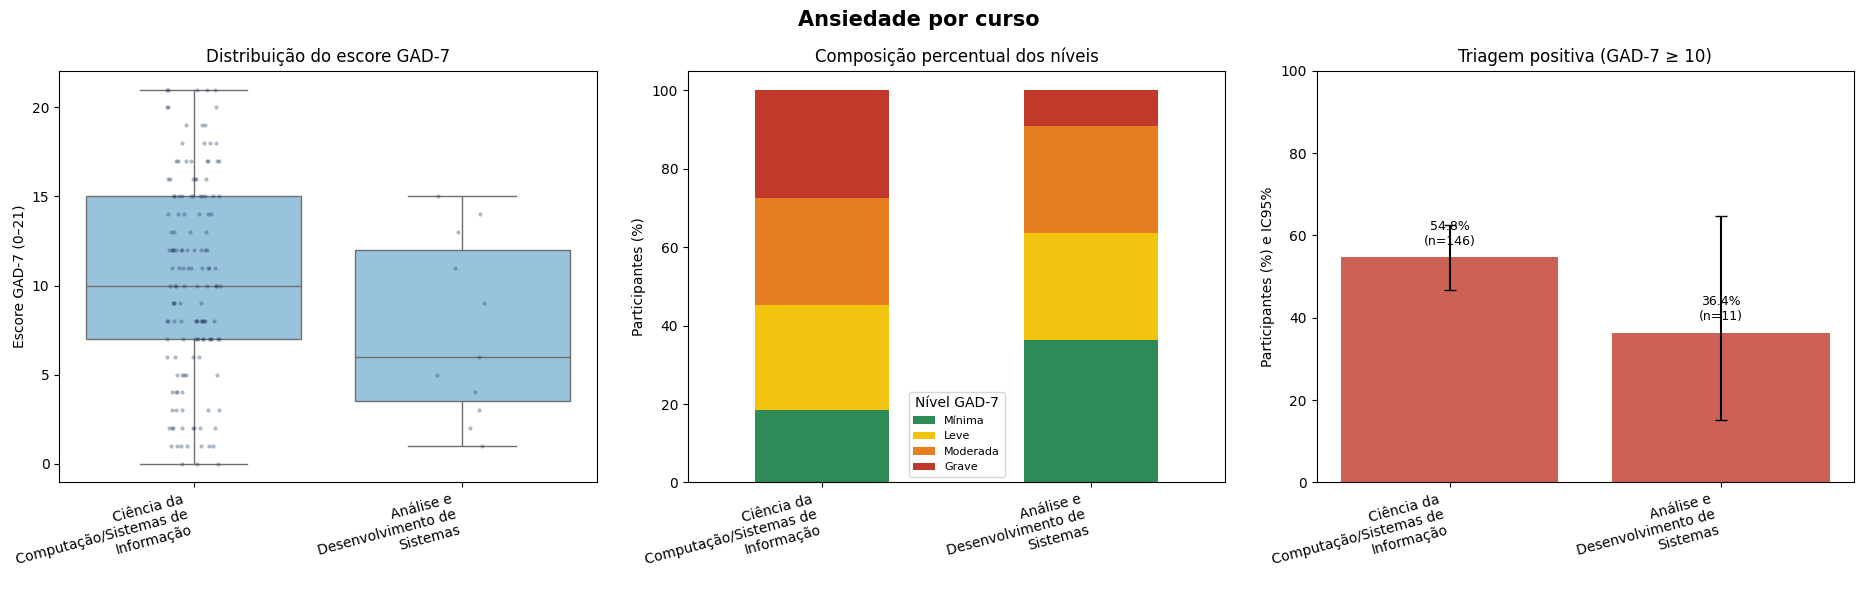

**Interpretação:** o maior escore médio foi observado em **Ciência da Computação/Sistemas de Informação** (10.2) e o menor em **Análise e Desenvolvimento de Sistemas** (7.5). O teste Mann-Whitney não indica diferença estatisticamente significativa após correção por múltiplas comparações (p ajustado = 0,988). Para a triagem positiva, o teste Qui-quadrado de Pearson não indica associação estatisticamente significativa (p ajustado = 0,988).

In [ ]:
exibir_analise_dimensao(analise_gad, 'curso')

### 2. Relação entre modalidade e ansiedade

,Modalidade,n,GAD-7 (média ± DP),Mediana GAD-7,Triagem positiva,IC95% da triagem
0,EaD,50,9.7 ± 5.5,10.5,52.0% (26/50),38.5%–65.2%
1,Presencial,136,10.5 ± 5.6,10.5,56.6% (77/136),48.2%–64.7%


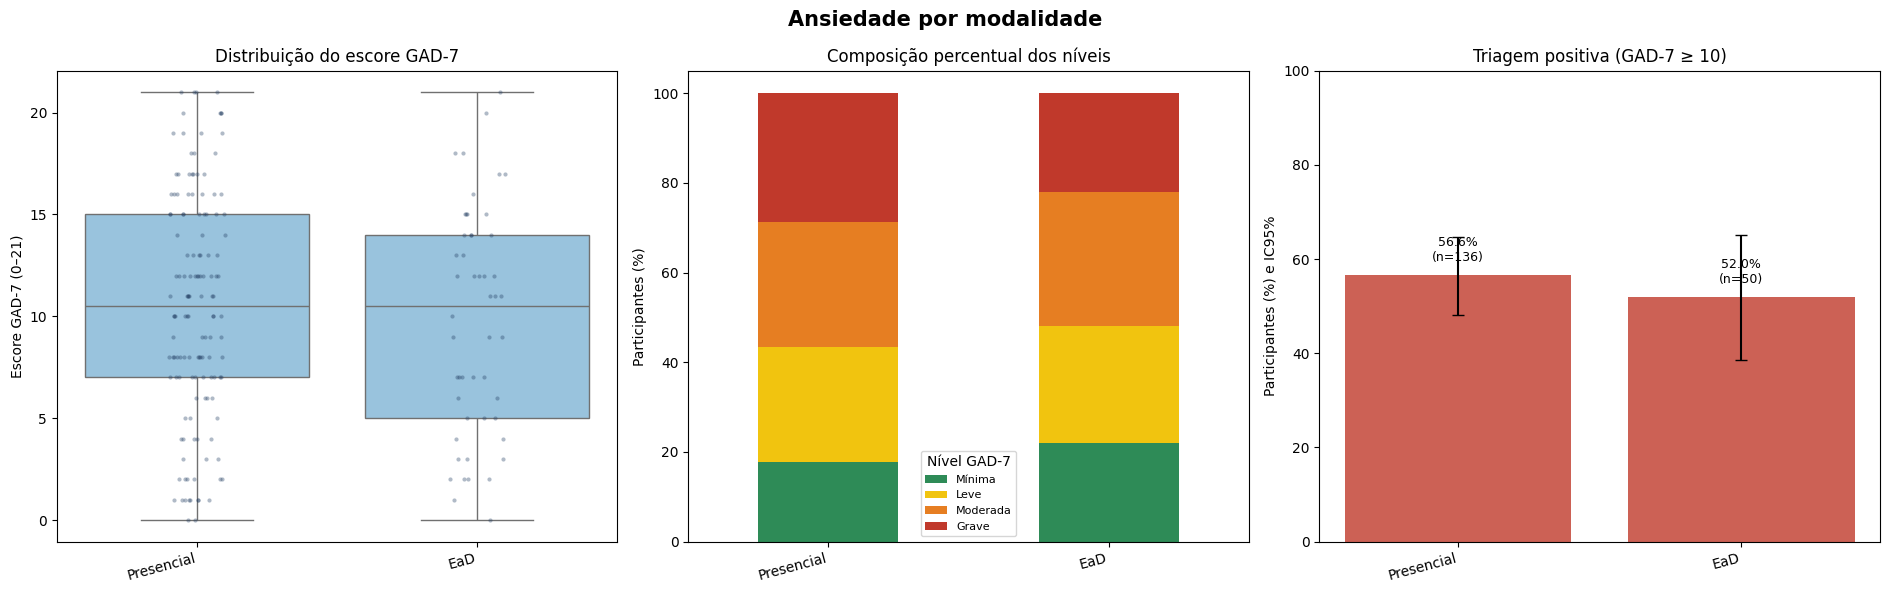

**Interpretação:** o maior escore médio foi observado em **Presencial** (10.5) e o menor em **EaD** (9.7). O teste Mann-Whitney não indica diferença estatisticamente significativa após correção por múltiplas comparações (p ajustado = 0,988). Para a triagem positiva, o teste Qui-quadrado de Pearson não indica associação estatisticamente significativa (p ajustado = 0,988).

In [ ]:
exibir_analise_dimensao(analise_gad, 'modalidade')

### 3. Relação entre turno e ansiedade

,Turno,n,GAD-7 (média ± DP),Mediana GAD-7,Triagem positiva,IC95% da triagem
0,Matutino,67,10.2 ± 5.4,11.0,56.7% (38/67),44.8%–67.9%
1,Noturno,110,10.4 ± 5.8,10.0,55.5% (61/110),46.1%–64.4%


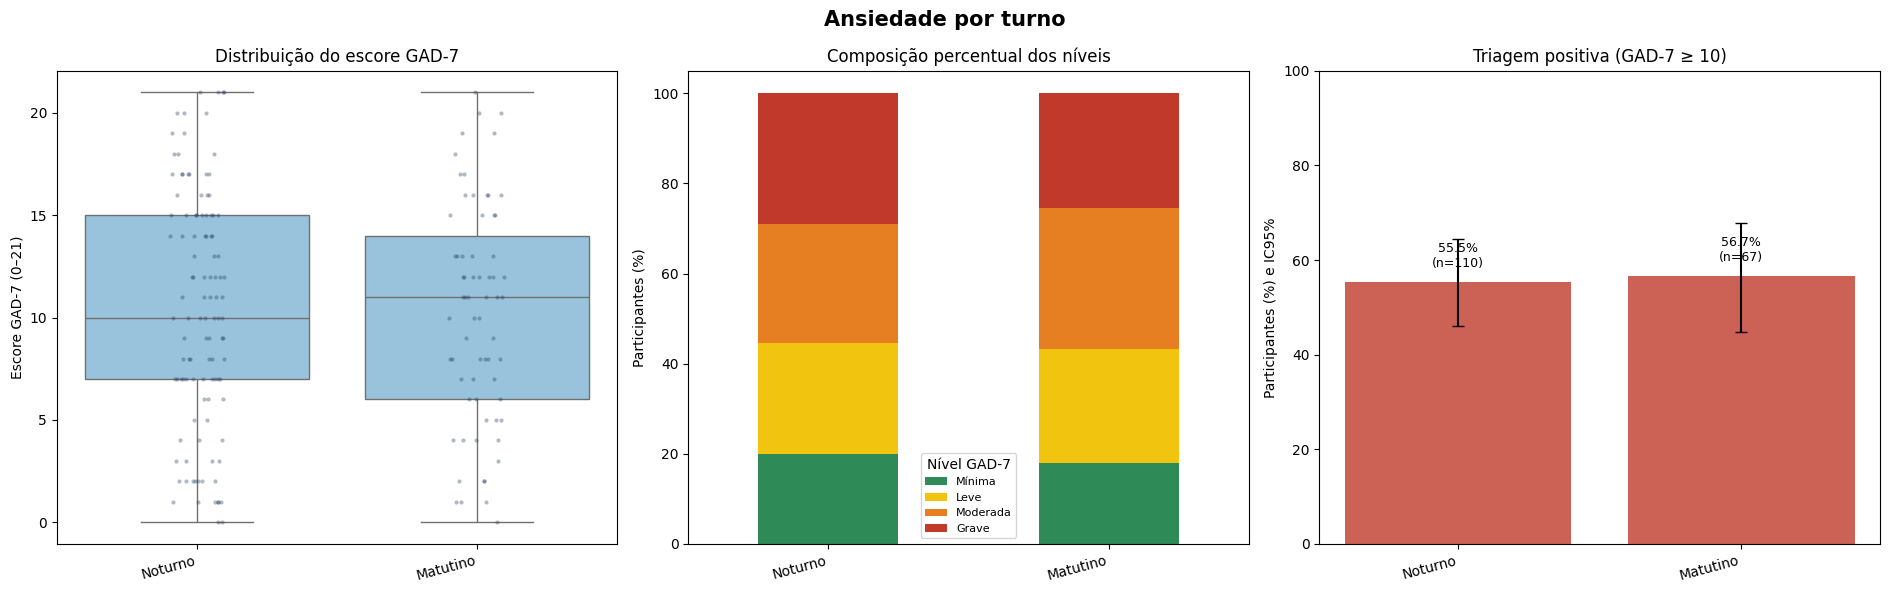

**Interpretação:** o maior escore médio foi observado em **Noturno** (10.4) e o menor em **Matutino** (10.2). O teste Mann-Whitney não indica diferença estatisticamente significativa após correção por múltiplas comparações (p ajustado = 0,988). Para a triagem positiva, o teste Qui-quadrado de Pearson não indica associação estatisticamente significativa (p ajustado = 0,994).

In [ ]:
exibir_analise_dimensao(analise_gad, 'turno')

### 4. Faculdade: verificação de suficiência amostral

In [ ]:
contagem_faculdades = analise_gad['faculdade'].value_counts().rename_axis('Faculdade').reset_index(name='n')
display(contagem_faculdades)
faculdades_elegiveis = contagem_faculdades.loc[contagem_faculdades['n'].ge(MIN_GRUPO), 'Faculdade']
if len(faculdades_elegiveis) < 2:
    display(Markdown(
        '**Conclusão:** não foi calculada associação entre faculdade e ansiedade, '
        'pois menos de duas faculdades possuem pelo menos 10 participantes.'
    ))

,Faculdade,n
0,FCI,166
1,Não determinada,12
2,FDIR,7
3,CCL,1


# Modelos ajustados

São estimados modelos separados para curso, modalidade e turno. O modelo linear usa erros robustos HC3 para o escore GAD-7; o modelo de Poisson robusto estima razões de prevalência para triagem positiva. Os controles ordinais são codificados por pontos médios ou escores ordenados explicitamente definidos abaixo.

In [ ]:
try:
    import statsmodels.api as sm
    import statsmodels.formula.api as smf
    from statsmodels.stats.outliers_influence import variance_inflation_factor
except ImportError as erro:
    raise ImportError(
        'A análise ajustada requer a biblioteca statsmodels. '
        'Instale-a no ambiente do notebook antes de executar esta seção.'
    ) from erro

def mapear_ordinal(serie, mapa):
    return serie.apply(lambda valor: mapa.get(chave_texto(valor), np.nan))

base_modelos = analise_gad.copy()
base_modelos['semestre_ord'] = mapear_ordinal(base_modelos['Semestre Atual'], {
    '1-2': 1.5, '3-4': 3.5, '5-6': 5.5, '7-8': 7.5, '9+': 9.0
})
base_modelos['horas_sono_ord'] = mapear_ordinal(base_modelos['Horas de sono por noite'], {
    '<5': 4.5, '5-6': 5.5, '7-8': 7.5, '>8': 9.0
})
base_modelos['qualidade_sono_ord'] = mapear_ordinal(base_modelos['Qualidade do sono (últimas 2 semanas)'], {
    'pessima': 1, 'ruim': 2, 'regular': 3, 'boa': 4, 'otima': 5
})
base_modelos['atividade_ord'] = mapear_ordinal(base_modelos['Atividade física semanal'], {
    '0 dias': 0, '1-2 dias': 1.5, '3-4 dias': 3.5, '> 5 dias': 6
})
base_modelos['alimentacao_ord'] = mapear_ordinal(base_modelos['Alimentação adequada (autoavaliação)'], {
    'muito baixa': 1, 'baixa': 2, 'media': 3, 'alta': 4, 'muito alta': 5
})
base_modelos['estudos_ord'] = mapear_ordinal(base_modelos['Carga diária de estudos fora da aula'], {
    '<1 hora': 0.5, '1-2 horas': 1.5, '3-4 horas': 3.5, '>4 horas': 5
})
base_modelos['lazer_ord'] = mapear_ordinal(base_modelos['Tempo de lazer/descanso por dia'], {
    '<30 minutos': 0.25, '30-60 minutos': 0.75, '1-2 horas': 1.5, '>2 horas': 2.5
})
base_modelos['trabalho_modelo'] = base_modelos['Trabalha atualmente?'].where(
    ~base_modelos['Trabalha atualmente?'].apply(chave_texto).eq('prefiro nao informar')
)

CONTROLES_MODELO = [
    'semestre_ord', 'trabalho_modelo', 'horas_sono_ord',
    'qualidade_sono_ord', 'atividade_ord', 'alimentacao_ord',
    'estudos_ord', 'lazer_ord'
]
REFERENCIAS_MODELO = {
    'curso': 'Ciência da Computação/Sistemas de Informação',
    'modalidade': 'Presencial',
    'turno': 'Matutino'
}

def maximo_vif(modelo):
    matriz = np.asarray(modelo.model.exog, dtype=float)
    nomes = list(modelo.model.exog_names)
    valores = []
    for indice, nome in enumerate(nomes):
        if nome.lower() == 'intercept':
            continue
        try:
            valores.append(variance_inflation_factor(matriz, indice))
        except (ValueError, np.linalg.LinAlgError):
            valores.append(np.inf)
    return max(valores) if valores else np.nan

def extrair_efeitos(modelo, dimensao, desfecho):
    linhas = []
    intervalos = modelo.conf_int()
    for termo in modelo.params.index:
        if not termo.startswith(f'C({dimensao}, Treatment'):
            continue
        estimativa = modelo.params[termo]
        inferior, superior = intervalos.loc[termo]
        if desfecho == 'triagem_positiva':
            estimativa, inferior, superior = np.exp([estimativa, inferior, superior])
            medida = 'Razão de prevalência ajustada'
        else:
            medida = 'Diferença ajustada no escore'
        correspondencia = re.search(r'\[T\.(.*)\]$', termo)
        categoria = correspondencia.group(1) if correspondencia else termo
        linhas.append({
            'dimensao': dimensao, 'desfecho': desfecho, 'termo': termo,
            'comparacao': f'{categoria} vs {REFERENCIAS_MODELO[dimensao]}',
            'medida': medida, 'estimativa': estimativa,
            'ic95_inferior': inferior, 'ic95_superior': superior,
            'p_valor': modelo.pvalues[termo]
        })
    return linhas

def ajustar_dimensao(dimensao):
    base, _ = grupos_elegiveis(base_modelos, dimensao)
    colunas_necessarias = [
        dimensao, 'score_gad7', 'triagem_positiva',
        *CONTROLES_MODELO
    ]
    base = base[colunas_necessarias].dropna().copy()
    referencia = REFERENCIAS_MODELO[dimensao]
    if referencia not in set(base[dimensao]):
        raise ValueError(f'Referência {referencia!r} ausente em {dimensao}.')
    exposicao = f"C({dimensao}, Treatment(reference={referencia!r}))"
    controles = (
        'semestre_ord + C(trabalho_modelo) + horas_sono_ord + '
        'qualidade_sono_ord + atividade_ord + alimentacao_ord + '
        'estudos_ord + lazer_ord'
    )
    modelo_score = smf.ols(
        f'score_gad7 ~ {exposicao} + {controles}', data=base
    ).fit(cov_type='HC3')
    modelo_prevalencia = smf.glm(
        f'triagem_positiva ~ {exposicao} + {controles}',
        data=base, family=sm.families.Poisson()
    ).fit(cov_type='HC3')
    efeitos = (
        extrair_efeitos(modelo_score, dimensao, 'score_gad7') +
        extrair_efeitos(modelo_prevalencia, dimensao, 'triagem_positiva')
    )
    menor_classe = min(base['triagem_positiva'].sum(), (1 - base['triagem_positiva']).sum())
    diagnostico = {
        'dimensao': dimensao, 'n_modelo': len(base),
        'parametros': int(len(modelo_prevalencia.params)),
        'menor_classe_por_parametro': menor_classe / len(modelo_prevalencia.params),
        'max_vif': maximo_vif(modelo_score),
        'convergiu_poisson': bool(modelo_prevalencia.converged)
    }
    return efeitos, diagnostico, modelo_score, modelo_prevalencia

,Dimensão,Comparação,Diferença no GAD-7 (IC95%),p ajustado — escore,RP ajustada (IC95%),p ajustado — triagem
0,curso,Análise e Desenvolvimento de Sistemas vs Ciênc...,-0.05 (-3.38; 3.29),"0,978",0.88 (0.39; 2.00),"0,978"
1,modalidade,EaD vs Presencial,0.91 (-1.23; 3.04),"0,978",1.06 (0.72; 1.56),"0,978"
2,turno,Noturno vs Matutino,0.80 (-1.33; 2.93),"0,978",0.96 (0.68; 1.36),"0,978"


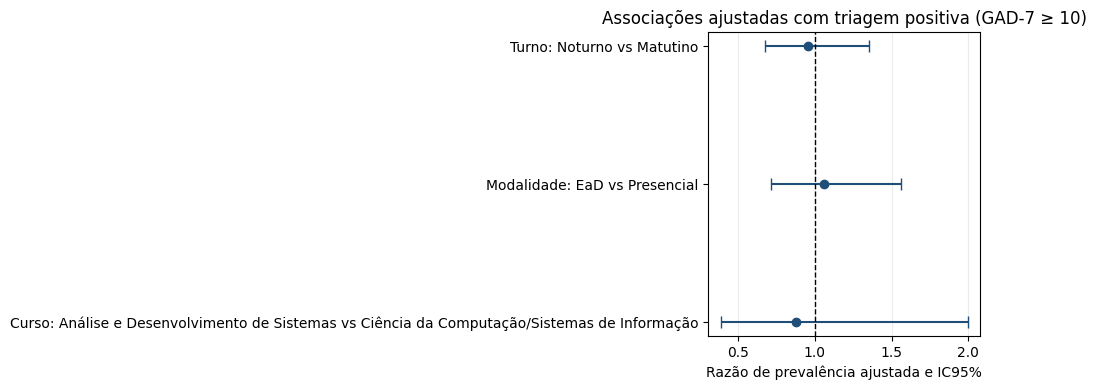

**Conclusão ajustada:** curso, modalidade e turno não apresentaram associação estatisticamente significativa com o escore ou com a triagem positiva após os ajustes.

In [ ]:
efeitos_ajustados = []
diagnosticos_modelos = []
modelos_ajustados = {}

for dimensao in DIMENSOES_ANALISE:
    efeitos, diagnostico, modelo_score, modelo_prevalencia = ajustar_dimensao(dimensao)
    efeitos_ajustados.extend(efeitos)
    diagnosticos_modelos.append(diagnostico)
    modelos_ajustados[dimensao] = {
        'score': modelo_score,
        'prevalencia': modelo_prevalencia
    }

tabela_efeitos_ajustados = pd.DataFrame(efeitos_ajustados)
tabela_efeitos_ajustados['p_ajustado_bh'] = corrigir_bh(tabela_efeitos_ajustados['p_valor'])
tabela_efeitos_ajustados['significativo_5pct'] = tabela_efeitos_ajustados['p_ajustado_bh'].lt(ALPHA)
tabela_diagnosticos = pd.DataFrame(diagnosticos_modelos)

efeitos_score = tabela_efeitos_ajustados.loc[
    tabela_efeitos_ajustados['desfecho'].eq('score_gad7')
].set_index('dimensao')
efeitos_prevalencia = tabela_efeitos_ajustados.loc[
    tabela_efeitos_ajustados['desfecho'].eq('triagem_positiva')
].set_index('dimensao')
tabela_modelos_compacta = pd.DataFrame(index=DIMENSOES_ANALISE)
tabela_modelos_compacta['Comparação'] = efeitos_score['comparacao']
tabela_modelos_compacta['Diferença no GAD-7 (IC95%)'] = efeitos_score.apply(
    lambda linha: f"{linha['estimativa']:.2f} ({linha['ic95_inferior']:.2f}; {linha['ic95_superior']:.2f})", axis=1
)
tabela_modelos_compacta['p ajustado — escore'] = efeitos_score['p_ajustado_bh'].map(formatar_p)
tabela_modelos_compacta['RP ajustada (IC95%)'] = efeitos_prevalencia.apply(
    lambda linha: f"{linha['estimativa']:.2f} ({linha['ic95_inferior']:.2f}; {linha['ic95_superior']:.2f})", axis=1
)
tabela_modelos_compacta['p ajustado — triagem'] = efeitos_prevalencia['p_ajustado_bh'].map(formatar_p)
display(tabela_modelos_compacta.rename_axis('Dimensão').reset_index())

if (tabela_diagnosticos['max_vif'] >= 5).any():
    display(Markdown('**Atenção:** pelo menos um modelo apresentou VIF ≥ 5; interprete seus coeficientes com cautela.'))
if (tabela_diagnosticos['menor_classe_por_parametro'] < 5).any():
    display(Markdown('**Atenção:** pelo menos um modelo tem poucos casos por parâmetro; considere reduzir controles ou ampliar a amostra.'))

forest = tabela_efeitos_ajustados.loc[
    tabela_efeitos_ajustados['desfecho'].eq('triagem_positiva')
].copy()
forest['rotulo'] = forest['dimensao'].str.title() + ': ' + forest['comparacao']
forest = forest.reset_index(drop=True)
figura, eixo = plt.subplots(figsize=(10, max(4, 0.8 * len(forest))))
posicoes = np.arange(len(forest))
eixo.errorbar(
    forest['estimativa'], posicoes,
    xerr=[
        forest['estimativa'] - forest['ic95_inferior'],
        forest['ic95_superior'] - forest['estimativa']
    ],
    fmt='o', color='#1F4E79', capsize=4
)
eixo.axvline(1, color='black', linestyle='--', linewidth=1)
eixo.set_yticks(posicoes, forest['rotulo'])
eixo.set_xlabel('Razão de prevalência ajustada e IC95%')
eixo.set_title('Associações ajustadas com triagem positiva (GAD-7 ≥ 10)')
eixo.grid(axis='x', alpha=0.25)
figura.tight_layout()
plt.show()

if tabela_efeitos_ajustados['significativo_5pct'].any():
    display(Markdown(
        '**Conclusão:** pelo menos uma associação permaneceu estatisticamente significativa '
        'após o controle das demais variáveis e a correção por múltiplas comparações.'
    ))
else:
    display(Markdown(
        '**Conclusão ajustada:** curso, modalidade e turno não apresentaram associação '
        'estatisticamente significativa com o escore ou com a triagem positiva após os ajustes.'
    ))

#### Aprendizado Não-Supervisionado: Clusters

In [ ]:
df_cluster = df.copy()

features_cluster = ['Horas de sono por noite',
    'Qualidade do sono (últimas 2 semanas)',
    'Atividade física semanal',
    'Alimentação adequada (autoavaliação)',
    'Carga diária de estudos fora da aula',
    'Tempo de lazer/descanso por dia']

variaveis_gad7 = ['Score GAD-7',
                  'Nível',
                  'Ansiedade']

ordens_features = {
    'Horas de sono por noite' : ['<5','5-6','7-8','>8'],
    'Qualidade do sono (últimas 2 semanas)': ['Péssima','Ruim','Regular','Boa','Ótima'],
    'Atividade física semanal' : ['0 dias','1-2 dias','3-4 dias','> 5 dias'],
    'Alimentação adequada (autoavaliação)' : ['Muito baixa','Baixa','Média','Alta','Muito Alta'],
    'Carga diária de estudos fora da aula' : ['<1 hora','1-2 horas','3-4 horas','>4 horas'],
    'Tempo de lazer/descanso por dia' : ['<30 minutos','30-60 minutos','1-2 horas','>2 horas']
}

In [ ]:
# Transforma as categorias em números ordinais
df_ordem = df_cluster[features_cluster + variaveis_gad7].copy()

for coluna in features_cluster:
    df_ordem[coluna] = pd.Categorical(
        df_ordem[coluna],
        categories=ordens_features[coluna],
        ordered=True
    ).codes

In [ ]:
# Padronização dos números com Z-Score
df_padronizado = df_ordem[features_cluster].copy()

for coluna in features_cluster:
    df_padronizado[coluna] = (
        df_padronizado[coluna] - df_padronizado[coluna].mean()
    ) / df_padronizado[coluna].std()

x = df_padronizado[features_cluster].to_numpy()

In [ ]:
candidatos_lenclusters = range(2,11)
inercia_candidatos = []

for candidatos in candidatos_lenclusters:
    kmed_model = KMedoids(n_clusters=candidatos, metric="euclidean", method="alternate", init="build", random_state=42, max_iter=1000)
    kmed_model.fit(x)
    inercia_candidatos.append(kmed_model.inertia_)

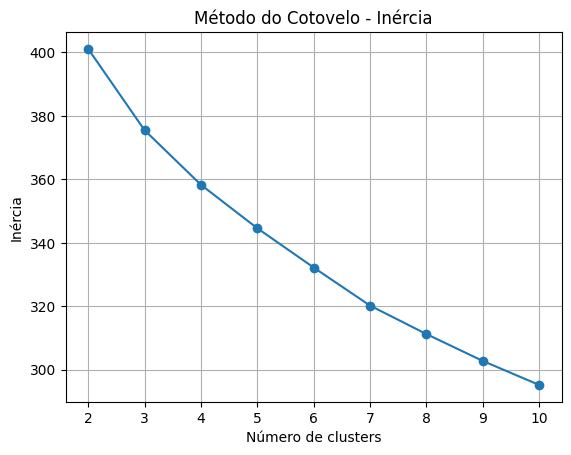

In [ ]:
plt.title("Método do Cotovelo - Inércia")
plt.xlabel("Número de clusters")
plt.ylabel("Inércia")
plt.xticks(candidatos_lenclusters)
plt.grid()
plt.plot(candidatos_lenclusters, inercia_candidatos, marker='o')
plt.show()

In [ ]:
def dunn_index(x, labels):
  distancias = pairwise_distances(x, metric='euclidean')
  clusters = np.unique(labels)

  maior_diametro = 0
  for cluster in clusters:
    cluster_indices = np.where(labels == cluster)[0]

    if len(cluster_indices) > 1:
      cluster_distancias = distancias[np.ix_(cluster_indices, cluster_indices)]
      diametro = cluster_distancias.max()
      maior_diametro = max(maior_diametro, diametro)

  if maior_diametro == 0:
    return np.nan

  menor_distancia = np.inf

  for i, cluster_i in enumerate(clusters):
    cluster_i = np.where(labels == cluster_i)[0]
    for j, cluster_j in enumerate(clusters):
      if j <= i:
        continue
      cluster_j = np.where(labels == cluster_j)[0]
      cluster_entredistancias = distancias[np.ix_(cluster_i, cluster_j)].min()
      menor_distancia = min(menor_distancia, cluster_entredistancias)

  return menor_distancia / maior_diametro

In [ ]:
kmed_results = []
modelos_candidatos = {}
labels_candidatos = {}

for k in range(2,11):
  kmed_model = KMedoids(n_clusters=k, metric="euclidean", method="alternate", init="build", random_state=42, max_iter=1000)
  labels = kmed_model.fit_predict(x)
  modelos_candidatos[k] = kmed_model
  labels_candidatos[k] = labels
  kmed_results.append({
      "K": k,
      "Inércia": kmed_model.inertia_,
      "Silhueta": silhouette_score(x, labels),
      "Davies-Bouldin": davies_bouldin_score(x, labels),
      "Calinski-Harabasz": calinski_harabasz_score(x, labels),
      "Índice de Dunn": dunn_index(x, labels),
      "Menor cluster": pd.Series(labels).value_counts().min(),
      "Maior cluster": pd.Series(labels).value_counts().max()
  })

df_metricas = pd.DataFrame(kmed_results)
display(df_metricas.round(4))

,K,Inércia,Silhueta,Davies-Bouldin,Calinski-Harabasz,Índice de Dunn,Menor cluster,Maior cluster
0,2,401.1056,0.1806,1.8713,43.1224,0.1495,66,120
1,3,375.5002,0.1405,2.0166,36.1399,0.1657,42,79
2,4,358.2903,0.1197,2.0876,30.0692,0.1678,40,58
3,5,344.6048,0.1142,2.0685,25.9748,0.1678,21,46
4,6,332.2243,0.1185,1.8554,25.8988,0.1678,13,41
5,7,320.2296,0.1129,1.7667,23.8823,0.1714,13,40
6,8,311.2570,0.1141,1.7206,22.9685,0.1714,13,40
7,9,302.7879,0.1163,1.6963,21.8713,0.1714,13,32
8,10,295.2249,0.1160,1.6680,20.7958,0.1714,11,30


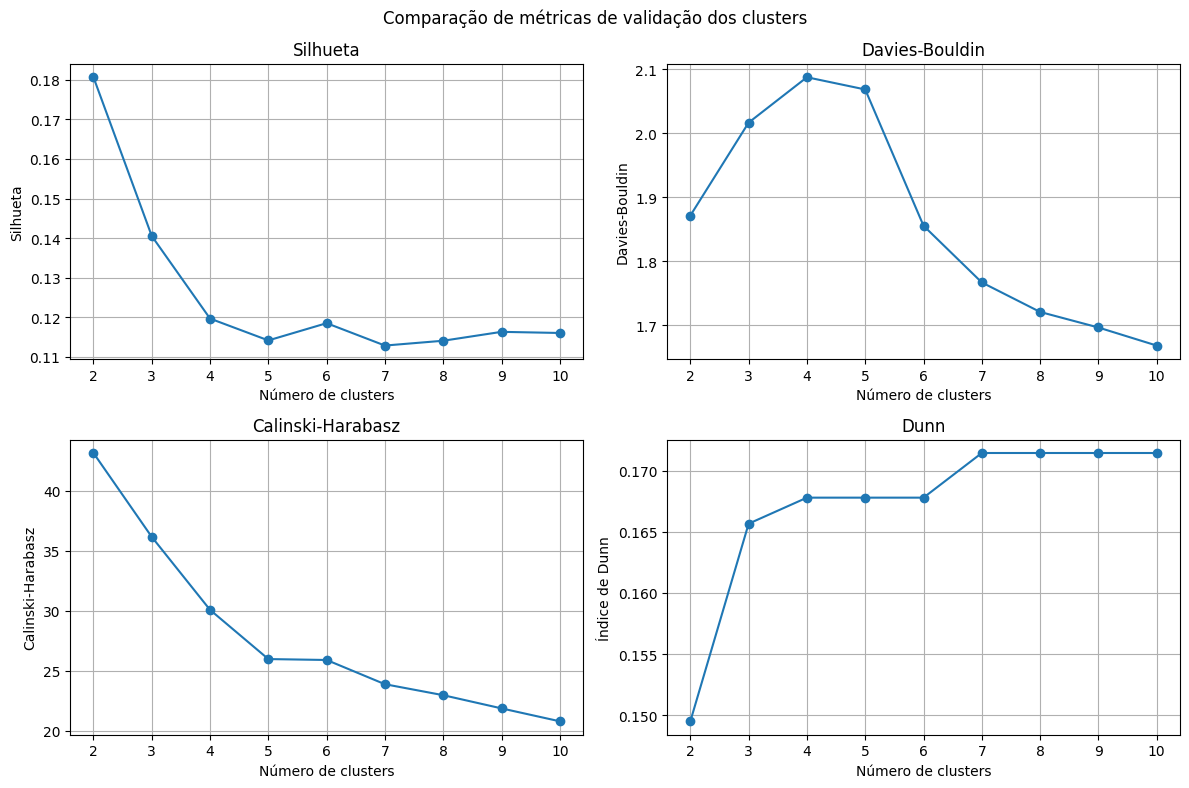

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

metricas = [("Silhueta","Silhueta"),("Davies-Bouldin","Davies-Bouldin"),("Calinski-Harabasz","Calinski-Harabasz"),("Índice de Dunn","Dunn")]

for ax, (coluna, titulo) in zip(axes.flat, metricas):
  ax.plot(df_metricas["K"], df_metricas[coluna], marker='o')
  ax.set_title(titulo)
  ax.set_xlabel("Número de clusters")
  ax.set_ylabel(coluna)
  ax.set_xticks(df_metricas["K"])
  ax.grid()

plt.suptitle("Comparação de métricas de validação dos clusters")
plt.tight_layout()
plt.show()

##### K = [2, 3, 4] possuem os melhores índices, portanto iremos traçar qual deles é melhor para prosseguir.

In [ ]:
for k in range(2,5):
  df_perfil = df_cluster[features_cluster].copy()
  df_perfil["Cluster"] = labels_candidatos[k]
  tamanhos = df_perfil["Cluster"].value_counts().sort_index()

  print(f"\nTamanho dos clusters — K={k}")
  display(
      tamanhos.rename("Estudantes").to_frame()
      .assign(Percentual=lambda tabela:
              (tabela["Estudantes"] / len(df_perfil) * 100).round(1))
  )

  for coluna in features_cluster:
    print(f"\nDistribuição: {coluna}")
    distribuicao = pd.crosstab(
        df_perfil["Cluster"],
        df_perfil[coluna],
        normalize="index"
    ) * 100
    display(distribuicao.round(1))


Tamanho dos clusters — K=2


,Estudantes,Percentual
Cluster,,
0,120,64.5
1,66,35.5



Distribuição: Horas de sono por noite


Horas de sono por noite,5-6,7-8,<5,>8
Cluster,,,,
0,63.3,11.7,25.0,0.0
1,22.7,66.7,0.0,10.6



Distribuição: Qualidade do sono (últimas 2 semanas)


Qualidade do sono (últimas 2 semanas),Boa,Péssima,Regular,Ruim,Ótima
Cluster,,,,,
0,3.3,10.8,48.3,35.0,2.5
1,42.4,0.0,34.8,1.5,21.2


... (32 outputs left out)


Distribuição: Carga diária de estudos fora da aula


Carga diária de estudos fora da aula,1-2 horas,3-4 horas,<1 hora,>4 horas
Cluster,,,,
0,46.8,10.6,31.9,10.6
1,55.2,20.7,17.2,6.9
2,50.0,20.0,22.5,7.5
3,53.7,12.2,29.3,4.9



Distribuição: Tempo de lazer/descanso por dia


Tempo de lazer/descanso por dia,1-2 horas,30-60 minutos,<30 minutos,>2 horas
Cluster,,,,
0,42.6,29.8,0.0,27.7
1,29.3,17.2,1.7,51.7
2,7.5,40.0,42.5,10.0
3,24.4,41.5,24.4,9.8


In [ ]:
stable = df_padronizado.to_numpy()
proporcao_amostra = 0.80
n_execucoes = 50

n_amostras = int(len(stable)*proporcao_amostra)

resultados_subamostra = []

for k in range(2,5):
  partition = []
  for seed in range(n_execucoes):
    np.random.seed(seed)
    indices = np.random.choice(len(stable), n_amostras, replace=False)
    stable_amostra = stable[indices]
    kmed_model = KMedoids(n_clusters=k, metric="euclidean", method="alternate", init="build", random_state=42, max_iter=1000)
    labels = kmed_model.fit_predict(stable_amostra)
    partition.append(dict(zip(indices, labels)))

  aris = []
  for i, j in combinations(range(n_execucoes), 2):
    indices_comuns = sorted(set(partition[i]) & set(partition[j]))
    labels_i = [partition[i][indice] for indice in indices_comuns]
    labels_j = [partition[j][indice] for indice in indices_comuns]
    aris.append(adjusted_rand_score(labels_i, labels_j))
  resultados_subamostra.append({
      "K": k,
      "ARI médio": np.mean(aris),
      "ARI mediano": np.median(aris),
      "ARI desvio padrão": np.std(aris),
      "ARI mínimo": np.min(aris),
      "ARI máximo": np.max(aris)
  })

df_subamostra = pd.DataFrame(resultados_subamostra)
display(df_subamostra.round(4))

,K,ARI médio,ARI mediano,ARI desvio padrão,ARI mínimo,ARI máximo
0,2,0.3978,0.3914,0.3948,-0.0867,1.0
1,3,0.6899,0.6859,0.2617,0.1062,1.0
2,4,0.5323,0.4973,0.1870,0.1202,1.0


A solução com \(K=3\) foi selecionada como uma decisão exploratória, priorizando o detalhamento dos perfis de estilo de vida. Embora \(K=2\) apresente melhores valores de silhueta e Calinski–Harabasz, três grupos permitem investigar padrões mais específicos de hábitos. Essa escolha não indica superioridade geral de \(K=3\), uma vez que a silhueta de 0,1405 evidencia separação limitada entre os grupos. A decisão também deve considerar a estabilidade da solução e a interpretação dos perfis em comparação com \(K=2\).

In [ ]:
k_escolhido = 3

kmed_model_escolhido = modelos_candidatos[k_escolhido]
labels_escolhido = labels_candidatos[k_escolhido]

df_clusters = df_cluster[features_cluster + variaveis_gad7].copy()
df_clusters['Cluster'] = labels_escolhido

In [ ]:
len_clusters = df_clusters.groupby('Cluster').size()
len_clusters

,0
Cluster,
0,79
1,65
2,42


In [ ]:
percent_len_clusters = df_clusters.groupby('Cluster').size() / len(df_clusters) * 100
percent_len_clusters.round(2)

,0
Cluster,
0,42.47
1,34.95
2,22.58


In [ ]:
profile_clusters = df_clusters.groupby('Cluster')[features_cluster].agg(lambda coluna : coluna.mode().iloc[0])
profile_clusters

,Horas de sono por noite,Qualidade do sono (últimas 2 semanas),Atividade física semanal,Alimentação adequada (autoavaliação),Carga diária de estudos fora da aula,Tempo de lazer/descanso por dia
Cluster,,,,,,
0,5-6,Regular,1-2 dias,Média,1-2 horas,1-2 horas
1,7-8,Regular,0 dias,Média,1-2 horas,>2 horas
2,5-6,Ruim,0 dias,Baixa,1-2 horas,<30 minutos


In [ ]:
pd.crosstab(df_clusters['Cluster'], df_clusters['Horas de sono por noite'],normalize="index").mul(100).round(2)

Horas de sono por noite,5-6,7-8,<5,>8
Cluster,,,,
0,74.68,3.80,21.52,0.00
1,9.23,80.00,0.00,10.77
2,61.90,7.14,30.95,0.00


In [ ]:
pd.crosstab(df_clusters['Cluster'], df_clusters['Qualidade do sono (últimas 2 semanas)'],normalize="index").mul(100).round(2)

Qualidade do sono (últimas 2 semanas),Boa,Péssima,Regular,Ruim,Ótima
Cluster,,,,,
0,10.13,6.33,50.63,30.38,2.53
1,36.92,0.00,38.46,1.54,23.08
2,0.00,19.05,38.10,42.86,0.00


In [ ]:
pd.crosstab(df_clusters['Cluster'], df_clusters['Atividade física semanal'],normalize="index").mul(100).round(2)

Atividade física semanal,0 dias,1-2 dias,3-4 dias,> 5 dias
Cluster,,,,
0,21.52,35.44,29.11,13.92
1,32.31,21.54,30.77,15.38
2,73.81,26.19,0.00,0.00


In [ ]:
pd.crosstab(df_clusters['Cluster'], df_clusters['Alimentação adequada (autoavaliação)'],normalize="index").mul(100).round(2)

Alimentação adequada (autoavaliação),Alta,Baixa,Muito Alta,Muito baixa,Média
Cluster,,,,,
0,24.05,6.33,5.06,1.27,63.29
1,30.77,6.15,6.15,4.62,52.31
2,0.00,47.62,0.00,21.43,30.95


In [ ]:
pd.crosstab(df_clusters['Cluster'], df_clusters['Carga diária de estudos fora da aula'],normalize="index").mul(100).round(2)

Carga diária de estudos fora da aula,1-2 horas,3-4 horas,<1 hora,>4 horas
Cluster,,,,
0,51.90,11.39,27.85,8.86
1,53.85,20.00,20.00,6.15
2,47.62,19.05,26.19,7.14


In [ ]:
pd.crosstab(df_clusters['Cluster'], df_clusters['Tempo de lazer/descanso por dia'],normalize="index").mul(100).round(2)

Tempo de lazer/descanso por dia,1-2 horas,30-60 minutos,<30 minutos,>2 horas
Cluster,,,,
0,36.71,34.18,7.59,21.52
1,27.69,21.54,4.62,46.15
2,7.14,38.10,45.24,9.52


Cluster 0: Sono reduzido e hábitos intermediários

Cluster 1: Maior duração de sono e maior tempo de descanso

Cluster 2: Hábitos menos favoráveis e menor tempo de descanso

In [ ]:
nomes_clusters = {0: 'Sono reduzido e hábitos intermediários',
                  1: 'Maior duração de sono e maior tempo de descanso',
                  2: 'Hábitos menos favoráveis e menor tempo de descanso'}

df_clusters['Cluster'] = df_clusters['Cluster'].map(nomes_clusters)

In [ ]:
clusters_gad7 = df_clusters.groupby('Cluster')["Score GAD-7"].agg(Quantidade="count",Média="mean",Mediana="median",Desvio="std").round(2)
clusters_gad7

,Quantidade,Média,Mediana,Desvio
Cluster,,,,
Hábitos menos favoráveis e menor tempo de descanso,42,13.17,14.0,4.82
Maior duração de sono e maior tempo de descanso,65,8.48,9.0,5.93
Sono reduzido e hábitos intermediários,79,10.23,10.0,5.04


In [ ]:
def add_outlines(df_scattercluster, ax, colors_clusters):
  fator = np.sqrt(5.991)

  for cluster in df_scattercluster['Cluster'].unique():
    dados = df_scattercluster.loc[df_scattercluster['Cluster'] == cluster, ['PC1','PC2']].to_numpy()
    centroide = np.mean(dados, axis=0)
    cov = np.cov(dados, rowvar=False)

    autovalores, autovetores = np.linalg.eigh(cov)
    ordem = autovalores.argsort()[::-1]
    autovalores = autovalores[ordem]
    autovetores = autovetores[:, ordem]

    largura, altura = 2 * fator * np.sqrt(np.maximum(autovalores, 0))
    angulo = np.degrees(np.arctan2(autovetores[1, 0], autovetores[0, 0]))

    elipse = Ellipse(xy=centroide, width=largura, height=altura, angle=angulo, facecolor=colors_clusters[cluster], edgecolor=colors_clusters[cluster], fill=False, linewidth=2)

    ax.add_patch(elipse)

    ax.scatter(centroide[0],centroide[1],color=colors_clusters[cluster],edgecolor='black',linewidth=0.8,zorder=5,marker='X',s=200)

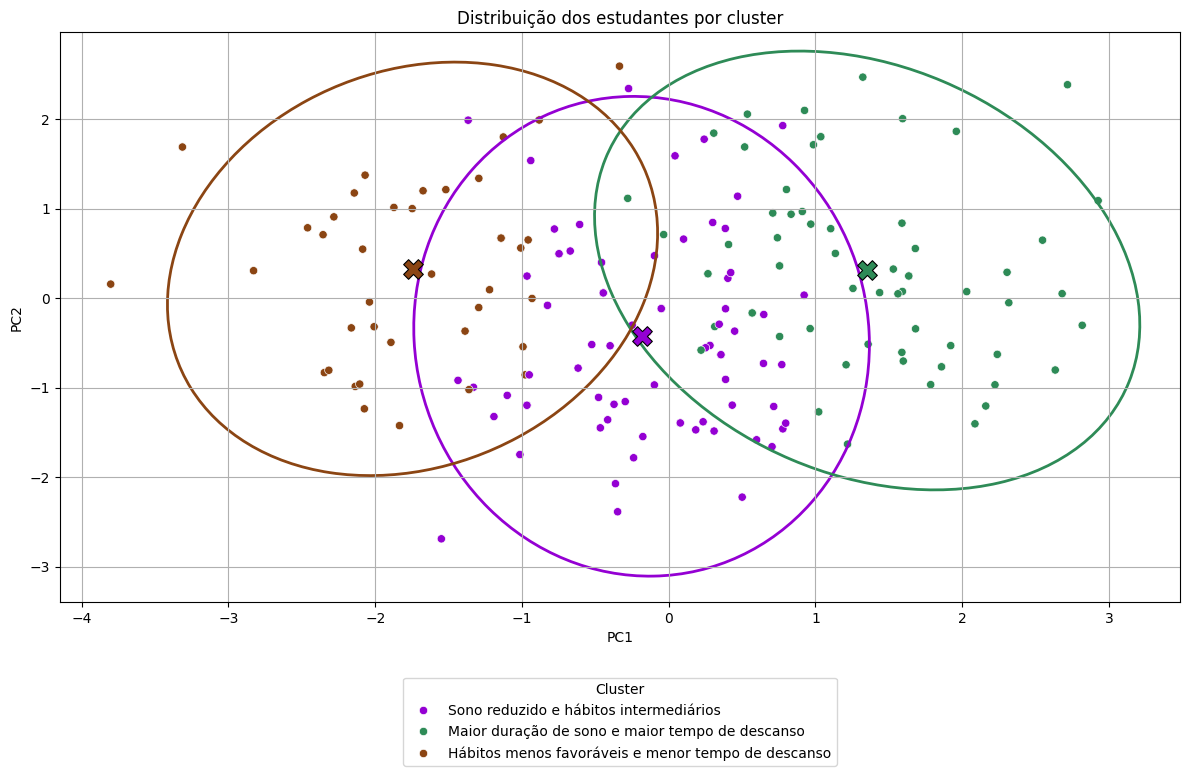

In [ ]:
pca = PCA(n_components=2)
coordenadas = pca.fit_transform(x)

df_pca = pd.DataFrame(coordenadas, columns=['PC1', 'PC2'])
df_scattercluster = df_pca.copy()
df_scattercluster['Cluster'] = df_clusters['Cluster'].to_numpy()

colors_clusters = {
    'Sono reduzido e hábitos intermediários': 'darkviolet',
    'Maior duração de sono e maior tempo de descanso': 'seagreen',
    'Hábitos menos favoráveis e menor tempo de descanso': 'saddlebrown'
}

fig, ax = plt.subplots(figsize=(12, 8))

sns.scatterplot(data=df_scattercluster,x="PC1",y="PC2",hue='Cluster',hue_order=list(colors_clusters.keys()),palette=colors_clusters,ax=ax)
add_outlines(df_scattercluster, ax, colors_clusters)
plt.title("Distribuição dos estudantes por cluster")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(title='Cluster',bbox_to_anchor=(0.5, -0.3), loc='lower center')
plt.tight_layout()
plt.grid()
plt.show()

In [ ]:
variancia = pca.explained_variance_ratio_ * 100

print(f"Variância PC1: {variancia[0].round(4)}%")
print(f"Variância PC2: {variancia[1].round(4)}%")
print(f"Variância acumulada: {variancia[:2].sum().round(4)}%")

Variância PC1: 30.3609%
Variância PC2: 19.7532%
Variância acumulada: 50.1141%


<Axes: ylabel='Cluster'>

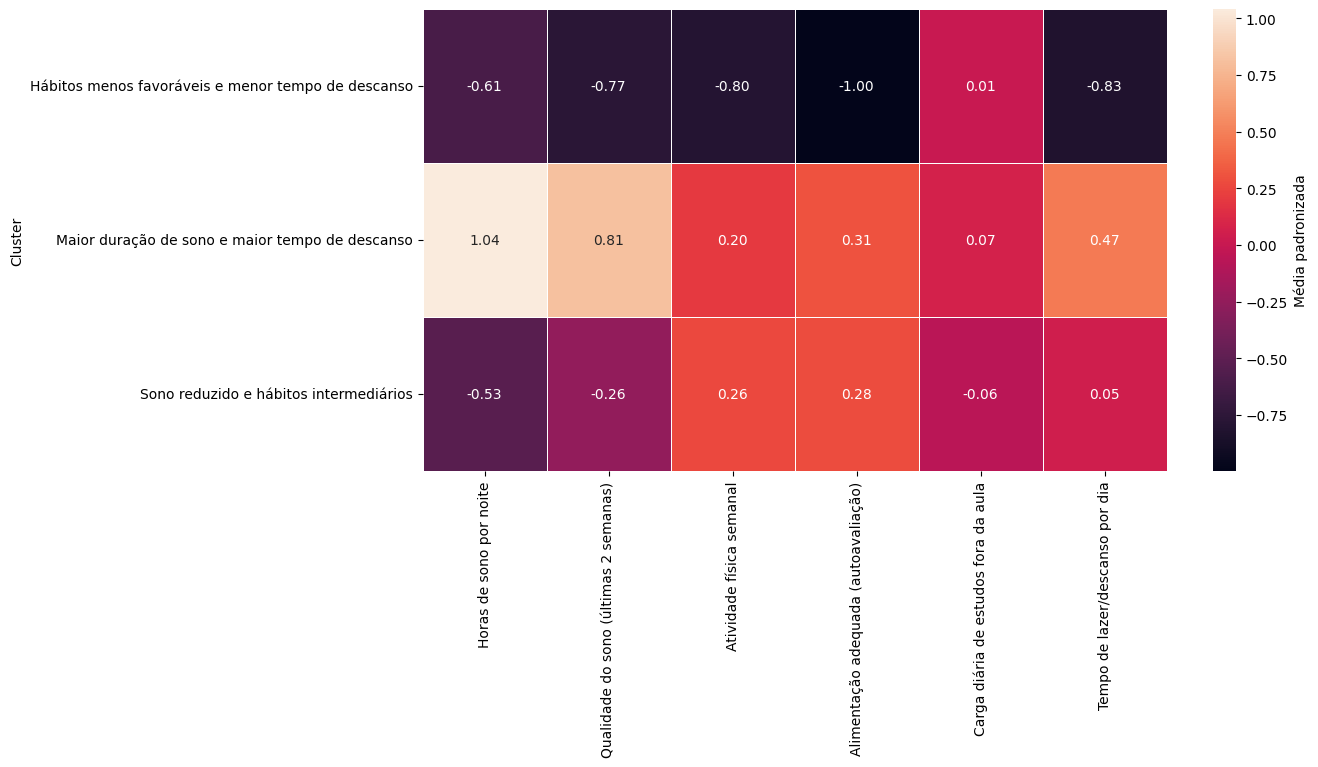

In [ ]:
df_heatmap = df_padronizado[features_cluster].copy()
df_heatmap['Cluster'] = df_clusters['Cluster'].to_numpy()

medias_clusters = (df_heatmap.groupby('Cluster')[features_cluster].mean())

plt.figure(figsize=(12, 6))
sns.heatmap(medias_clusters,annot=True,fmt=".2f",linewidths=0.5,cbar_kws={"label":"Média padronizada"})

In [ ]:
df_gad = df_cluster[["Score GAD-7"]].copy()
df_gad["Cluster"] = labels_candidatos[k_escolhido]

resumo_gad = (
    df_gad.groupby("Cluster", observed=True)["Score GAD-7"]
    .agg(
        Estudantes="count",
        Média="mean",
        Mediana="median",
        Desvio_padrão="std",
        Mínimo="min",
        Máximo="max"
    )
    .round(2)
)

resumo_gad.index = resumo_gad.index.map(nomes_clusters)

display(resumo_gad)

,Estudantes,Média,Mediana,Desvio_padrão,Mínimo,Máximo
Cluster,,,,,,
Sono reduzido e hábitos intermediários,79,10.23,10.0,5.04,1,21
Maior duração de sono e maior tempo de descanso,65,8.48,9.0,5.93,0,21
Hábitos menos favoráveis e menor tempo de descanso,42,13.17,14.0,4.82,4,21


In [ ]:
distribuicao_gad = pd.crosstab(
    df_gad["Cluster"],
    df_gad["Score GAD-7"],
    normalize="index"
) * 100

display(distribuicao_gad.round(1))

Score GAD-7,0,1,2,3,4,5,6,7,8,9,...,12,13,14,15,16,17,18,19,20,21
Cluster,,,,,,,,,,,,,,,,,,,,,
0,0.0,1.3,6.3,2.5,5.1,3.8,2.5,10.1,10.1,5.1,...,7.6,8.9,1.3,5.1,5.1,6.3,1.3,0.0,1.3,3.8
1,4.6,12.3,7.7,6.2,3.1,4.6,3.1,6.2,1.5,3.1,...,13.8,1.5,6.2,7.7,1.5,1.5,4.6,1.5,0.0,1.5
2,0.0,0.0,0.0,0.0,2.4,0.0,4.8,7.1,9.5,4.8,...,4.8,0.0,4.8,9.5,9.5,7.1,2.4,7.1,9.5,2.4


In [ ]:
grupos_gad = [
    df_gad.loc[df_gad["Cluster"] == cluster, "Score GAD-7"]
    for cluster in sorted(df_gad["Cluster"].unique())
]

estatistica_h, p_valor = kruskal(*grupos_gad)

n = sum(len(grupo) for grupo in grupos_gad)
k = len(grupos_gad)

epsilon_quadrado = max(0, (estatistica_h - k + 1) / (n - k))

print(f"Estatística H: {estatistica_h:.4f}")
print(f"Valor-p: {p_valor:.6f}")
print(f"Epsilon ao quadrado: {epsilon_quadrado:.4f}")

Estatística H: 16.2374
Valor-p: 0.000298
Epsilon ao quadrado: 0.0778


In [ ]:
teste_dunn = sp.posthoc_dunn(df_gad, val_col='Score GAD-7', group_col='Cluster', p_adjust='holm')
teste_dunn.round(3)

,0,1,2
0,1.000,0.088,0.015
1,0.088,1.000,0.000
2,0.015,0.000,1.000


In [ ]:
df_niveis = df_cluster[['Nível']].copy()
df_niveis['Cluster'] = labels_candidatos[k_escolhido]

pd_niveis = pd.crosstab(
    df_niveis['Cluster'],
    df_niveis['Nível'])

display(pd_niveis)

Nível,Mínima,Leve,Moderada,Grave
Cluster,,,,
0,12,25,24,18
1,22,12,19,12
2,1,11,10,20


In [ ]:
pd_percentniveis = pd.crosstab(
    df_niveis['Cluster'],
    df_niveis['Nível'],
    normalize='index'
) * 100

display(pd_percentniveis.round(1))

Nível,Mínima,Leve,Moderada,Grave
Cluster,,,,
0,15.2,31.6,30.4,22.8
1,33.8,18.5,29.2,18.5
2,2.4,26.2,23.8,47.6


In [ ]:
qui2, p_valor,  graus_liberdade, freq_esperada = chi2_contingency(pd_niveis)

print(f"Estatística Qui-Quadrado: {qui2:.4f}")
print(f"Valor-p: {p_valor:.6f}")
print(f"Graus de liberdade: {graus_liberdade}")
print("Frequência esperada:")
display(pd.DataFrame(freq_esperada.round(1), index=pd_niveis.index, columns=pd_niveis.columns))

Estatística Qui-Quadrado: 26.1502
Valor-p: 0.000209
Graus de liberdade: 6
Frequência esperada:


Nível,Mínima,Leve,Moderada,Grave
Cluster,,,,
0,14.9,20.4,22.5,21.2
1,12.2,16.8,18.5,17.5
2,7.9,10.8,12.0,11.3


<Figure size 1200x600 with 0 Axes>

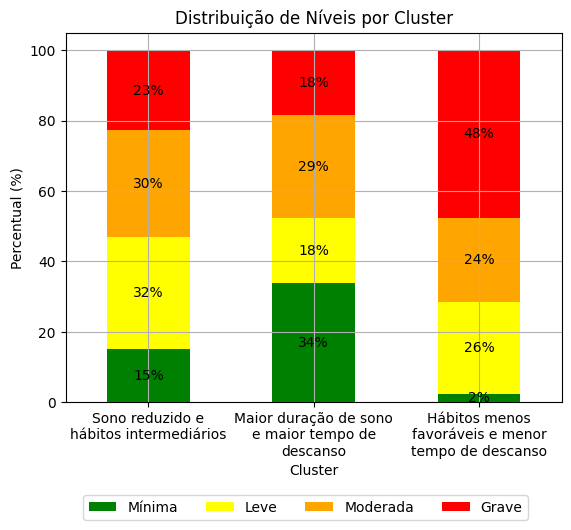

In [ ]:
clusters_nivel = (pd_niveis.div(pd_niveis.sum(axis=1), axis=0) * 100)
clusters_nivel.index = clusters_nivel.index.map(nomes_clusters)

plt.figure(figsize=(12, 6))
ax_clustersnivel = clusters_nivel.plot(kind='bar',stacked=True, color=nivel_cores)
ax_clustersnivel.set_title("Distribuição de Níveis por Cluster")
ax_clustersnivel.set_xlabel("Cluster")
ax_clustersnivel.set_ylabel("Percentual (%)")

break_names = ['\n'.join(textwrap.wrap(str(nome), width=22))
for nome in clusters_nivel.index]
ax_clustersnivel.set_xticklabels(break_names,rotation=0)

ax_clustersnivel.grid()

ax_clustersnivel.legend().remove()
handles, labels = ax_clustersnivel.get_legend_handles_labels()
plt.gcf().legend(handles,labels,loc='lower center',ncols=4,bbox_to_anchor=(0.5,-0.15))
add_labels(ax_clustersnivel)
plt.show()